# Proyecto #1 — Exploratory Data Analysis (EDA)
## Dataset: Predict Future Sales (Kaggle)

Ventas diarias de una cadena de tiendas rusas (1C Company). Objetivo final de la competencia: predecir las ventas
**mensuales** de cada par tienda-producto para noviembre de 2015. Este EDA prepara el terreno para el *forecasting*.

**Equipo:** alfredo.mux@galileo.edu · marco.garcia@galileo.edu · 25005795@galileo.edu

| Bloque | Secciones |
|---|---|
| 1 — Comprensión y calidad de los datos | 2, 3, 4 |
| 2 — Descriptivo, exploración temporal y comparación | 5, 6, 7 |
| 3 — Visualizaciones, ACF/PACF y conclusiones | 8, 9, 10 |

**Ramas por integrante:** `alfredo` · `mario` · `marco`

> Regla del equipo: avisar antes y después de modificar este notebook y editar solo las celdas de la sección propia.

## 0. Configuración

In [1]:
import warnings

from IPython.display import display

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

from predict_future_sales.config import FIGURES_DIR, PROCESSED_DATA_DIR, RAW_DATA_DIR
from predict_future_sales.dataset import (
    cargar_datos,
    convertir_cantidad_entera,
    convertir_fecha,
    limpiar_sales_train,
    MAPEO_TIENDAS_DUPLICADAS,
)

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

print("Datos crudos en:", RAW_DATA_DIR)

2026-11-15 00:41:51.240 -06:00 | INFO     | predict_future_sales.config:<module>:11 - PROJ_ROOT path is: C:\Users\MO\Desktop\Business Intelligence\8vo. trimestre\Product_Development\Clone\proyecto_predict_future_sales


Datos crudos en: C:\Users\MO\Desktop\Business Intelligence\8vo. trimestre\Product_Development\Clone\proyecto_predict_future_sales\data\raw


## 1. Estructura del proyecto y repositorio

- Estructura generada con **cookiecutter-data-science** v2 (ver `README.md`).
- Repositorio git publicado en GitHub (privado).
- `.gitignore` excluye los datos de Kaggle (`data/`, `*.csv`, `*.zip`).
- Screenshots del *pull* de cada integrante: ✅ completado (entregados por cada integrante).

## 2. Comprensión inicial del dataset

### 2.a Carga de archivos y primeras filas

In [2]:
# Carga de los 5 archivos originales (sin limpieza ni conversión de tipos)
datos = cargar_datos()

sales_train = datos["sales_train"]
items = datos["items"]
item_categories = datos["item_categories"]
shops = datos["shops"]
test = datos["test"]

for nombre, df in datos.items():
    print(f"\n=== {nombre} ===")
    display(df.head())


=== sales_train ===


,date,date_block_num,shop_id,item_id,item_price,item_cnt_day
0,02.01.2013,0,59,22154,999.00,1.0
1,03.01.2013,0,25,2552,899.00,1.0
2,05.01.2013,0,25,2552,899.00,-1.0
3,06.01.2013,0,25,2554,1709.05,1.0
4,15.01.2013,0,25,2555,1099.00,1.0



=== items ===


,item_name,item_id,item_category_id
0,! ВО ВЛАСТИ НАВАЖДЕНИЯ (ПЛАСТ.) D,0,40
1,!ABBYY FineReader 12 Professional Edition Full...,1,76
2,***В ЛУЧАХ СЛАВЫ (UNV) D,2,40
3,***ГОЛУБАЯ ВОЛНА (Univ) D,3,40
4,***КОРОБКА (СТЕКЛО) D,4,40



=== item_categories ===


,item_category_name,item_category_id
0,PC - Гарнитуры/Наушники,0
1,Аксессуары - PS2,1
2,Аксессуары - PS3,2
3,Аксессуары - PS4,3
4,Аксессуары - PSP,4



=== shops ===


,shop_name,shop_id
0,"!Якутск Орджоникидзе, 56 фран",0
1,"!Якутск ТЦ ""Центральный"" фран",1
2,"Адыгея ТЦ ""Мега""",2
3,"Балашиха ТРК ""Октябрь-Киномир""",3
4,"Волжский ТЦ ""Волга Молл""",4



=== test ===


,ID,shop_id,item_id
0,0,5,5037
1,1,5,5320
2,2,5,5233
3,3,5,5232
4,4,5,5268


**Interpretación:**

- `sales_train` es la tabla de hechos: cada fila es un producto vendido (o devuelto) en una tienda en un día. Ya en las primeras filas aparece una cantidad negativa (`item_cnt_day = -1`), es decir, una **devolución**.
- `items`, `item_categories` y `shops` son **catálogos** que dan nombre a los identificadores; `test` contiene los pares tienda-producto que se deben predecir para noviembre de 2015 (con un `ID` para la entrega).
- Relación entre tablas:
  - `sales_train` / `test` → `shops` por `shop_id`
  - `sales_train` / `test` → `items` por `item_id`
  - `items` → `item_categories` por `item_category_id`
- Los nombres de tiendas, productos y categorías están **en ruso**. Se observa que los nombres de categoría siguen el patrón `Grupo - Subgrupo` (p. ej. `Аксессуары - PS3` = Accesorios - PS3) y los de tienda empiezan con la ciudad; ambos patrones podrían aprovecharse más adelante para crear variables (tipo de categoría, ciudad).
- Algunos nombres traen caracteres especiales al inicio (`!`, `***`), por ejemplo en las tiendas 0 y 1 (`!Якутск ...`). Esto se revisará en la sección 4.c (tiendas repetidas).

### 2.b Tamaño de cada tabla

In [3]:
# Tamaño de cada tabla
tamanos = pd.DataFrame(
    {
        "filas": {n: df.shape[0] for n, df in datos.items()},
        "columnas": {n: df.shape[1] for n, df in datos.items()},
        "memoria_MB": {n: round(df.memory_usage(deep=True).sum() / 1e6, 1) for n, df in datos.items()},
    }
).rename_axis("tabla")
tamanos

,filas,columnas,memoria_MB
tabla,,,
sales_train,2935849,6,290.6
items,22170,3,3.5
item_categories,84,2,0.0
shops,60,2,0.0
test,214200,3,5.1


**Interpretación:**

- `sales_train` concentra prácticamente todo el volumen: **2,935,849 transacciones** en 6 columnas (~290 MB en memoria). Es la tabla sobre la que se hace todo el análisis; conviene evitar copias innecesarias de ella.
- Los catálogos son pequeños: **22,170 productos**, **84 categorías** y **60 tiendas**.
- `test` tiene **214,200 pares** tienda-producto a predecir.

### 2.c Descripción de columnas y variable objetivo

In [4]:
# Columnas de cada tabla con el tipo con el que pandas las leyó
pd.DataFrame(
    [(nombre, col, str(df[col].dtype)) for nombre, df in datos.items() for col in df.columns],
    columns=["tabla", "columna", "tipo_leido"],
)

,tabla,columna,tipo_leido
0,sales_train,date,str
1,sales_train,date_block_num,int64
2,sales_train,shop_id,int64
3,sales_train,item_id,int64
4,sales_train,item_price,float64
5,sales_train,item_cnt_day,float64
6,items,item_name,str
7,items,item_id,int64
8,items,item_category_id,int64
9,item_categories,item_category_name,str


**Descripción de las columnas:**

| Columna | Tabla | Descripción |
|---|---|---|
| `date` | sales_train | Fecha de la transacción. Viene como **texto** con formato `dd.mm.aaaa` (se convierte a *datetime* en la sección 3.b). |
| `date_block_num` | sales_train | Número de mes consecutivo: 0 = enero 2013, …, 33 = octubre 2015. |
| `shop_id` | sales_train, shops, test | Identificador de la tienda (sucursal). |
| `shop_name` | shops | Nombre de la tienda (en ruso; empieza con la ciudad). |
| `item_id` | sales_train, items, test | Identificador del producto. |
| `item_name` | items | Nombre del producto (en ruso). |
| `item_category_id` | items, item_categories | Identificador de la categoría del producto. |
| `item_category_name` | item_categories | Nombre de la categoría (en ruso, formato `Grupo - Subgrupo`). |
| `item_price` | sales_train | Precio unitario del producto en esa transacción (en rublos). |
| `item_cnt_day` | sales_train | Unidades vendidas en el día; **valores negativos = devoluciones**. |
| `ID` | test | Identificador de cada par tienda-producto a predecir (para la entrega). |
| `ingreso` *(derivada)* | — | No existe en el dataset; se construye como `item_price × item_cnt_day` (se usa desde la sección 5). |

**Variable objetivo:** la cantidad vendida **mensual** de cada par tienda-producto, es decir, `item_cnt_day` **sumada por mes** (`date_block_num`), `shop_id` e `item_id` (en la competencia se le llama `item_cnt_month`). Se debe predecir para noviembre de 2015, que corresponde a `date_block_num = 34`. En `sales_train` la información está a nivel diario, por lo que habrá que agregarla.

**Observación sobre tipos:** `item_cnt_day` fue leída como `float64` aunque representa unidades; `date` y los nombres como texto (`str`). La validación de tipos se hace en la sección 3.a.

### 2.d Rango temporal y meses cubiertos

In [5]:
# Rango temporal. La fecha se convierte SOLO para este cálculo (sin modificar sales_train);
# la conversión formal de la columna se hace en la sección 3.b.
fechas = pd.to_datetime(sales_train["date"], format="%d.%m.%Y")

print(f"Fecha mínima:                {fechas.min():%d-%m-%Y}")
print(f"Fecha máxima:                {fechas.max():%d-%m-%Y}")
print(f"Días en el rango:            {(fechas.max() - fechas.min()).days + 1:,}")
print(f"Días distintos con registros:{fechas.nunique():>6,}")
print()
print(f"date_block_num: de {sales_train['date_block_num'].min()} a {sales_train['date_block_num'].max()}")
print(f"Meses distintos (date_block_num): {sales_train['date_block_num'].nunique()}")
print(f"Meses calendario distintos (fecha): {fechas.dt.to_period('M').nunique()}")

Fecha mínima:                01-01-2013
Fecha máxima:                31-10-2015
Días en el rango:            1,034
Días distintos con registros: 1,034

date_block_num: de 0 a 33
Meses distintos (date_block_num): 34


Meses calendario distintos (fecha): 34


**Interpretación:**

- Los datos van del **01-01-2013 al 31-10-2015**: 1,034 días, que equivalen a **34 meses** completos.
- `date_block_num` va de **0 a 33** (34 valores), lo que coincide con los 34 meses calendario obtenidos de las fechas. La consistencia fila por fila entre `date` y `date_block_num` se valida en la sección 3.c.
- Hay registros en los 1,034 días del rango: a nivel de toda la cadena no hay días sin ninguna transacción (el detalle de días sin ventas por tienda/producto se revisa en la sección 3.c).
- El mes a predecir (noviembre 2015, `date_block_num = 34`) es el inmediatamente siguiente al último mes del historial. Con 34 meses se tienen menos de 3 ciclos anuales completos, lo cual limita (pero permite) observar estacionalidad anual.

## 3. Validación de la estructura de los datos

### 3.a Tipos de datos

In [6]:
# Tipo con el que pandas leyó cada columna vs. su tipo conceptual
tipo_conceptual = {
    "date": "Fecha (viene como texto)",
    "date_block_num": "Numérica ordinal (índice de mes)",
    "shop_id": "Categórica (identificador)",
    "item_id": "Categórica (identificador)",
    "item_category_id": "Categórica (identificador)",
    "ID": "Identificador de fila (test)",
    "item_price": "Numérica continua",
    "item_cnt_day": "Numérica discreta (unidades)",
    "item_name": "Categórica / texto",
    "item_category_name": "Categórica / texto",
    "shop_name": "Categórica / texto",
}
pd.DataFrame(
    [
        (nombre, col, str(df[col].dtype), tipo_conceptual[col])
        for nombre, df in datos.items()
        for col in df.columns
    ],
    columns=["tabla", "columna", "tipo_leido", "tipo_conceptual"],
)

,tabla,columna,tipo_leido,tipo_conceptual
0,sales_train,date,str,Fecha (viene como texto)
1,sales_train,date_block_num,int64,Numérica ordinal (índice de mes)
2,sales_train,shop_id,int64,Categórica (identificador)
3,sales_train,item_id,int64,Categórica (identificador)
4,sales_train,item_price,float64,Numérica continua
5,sales_train,item_cnt_day,float64,Numérica discreta (unidades)
6,items,item_name,str,Categórica / texto
7,items,item_id,int64,Categórica (identificador)
8,items,item_category_id,int64,Categórica (identificador)
9,item_categories,item_category_name,str,Categórica / texto


In [7]:
# item_cnt_day se leyó como float64 aunque representa unidades: ¿tiene decimales?
cnt = sales_train["item_cnt_day"]
print(f"Valores nulos:          {cnt.isna().sum()}")
print(f"Valores con decimales:  {(cnt % 1 != 0).sum()}")
print(f"Rango:                  {cnt.min():.0f} a {cnt.max():.0f}")

# Sin decimales -> se convierte a entero (función reutilizable en predict_future_sales/dataset.py)
sales_train = convertir_cantidad_entera(sales_train)
print(f"\nTipo de item_cnt_day después de convertir: {sales_train['item_cnt_day'].dtype}")

Valores nulos:          0
Valores con decimales:  0
Rango:                  -22 a 2169



Tipo de item_cnt_day después de convertir: int64


**Interpretación:**

- **Fecha:** `date` es la única variable temporal y pandas la leyó como texto (`str`); se convierte a *datetime* en 3.b.
- **Numéricas:** `item_price` (continua, `float64`) e `item_cnt_day` (discreta). `date_block_num` es numérica pero **ordinal**: indica el orden de los meses.
- **Categóricas:** `shop_id`, `item_id` e `item_category_id` se leyeron como enteros, pero son **identificadores**: no tiene sentido sumarlos ni promediarlos; se deben tratar como categorías (agrupar, contar, cruzar tablas). Los nombres (`shop_name`, `item_name`, `item_category_name`) son texto descriptivo.
- **`item_cnt_day`:** se leyó como `float64`, pero no tiene nulos ni decimales (rango de **-22 a 2,169** unidades), por lo que se convirtió a **entero** (`int64`). Los valores negativos son devoluciones y se analizan en la sección 4.b. Decisión registrada en DEC-006.

### 3.b Conversión de `date` a datetime (formato dd.mm.aaaa)

In [8]:
print(f"Tipo de date antes:   {sales_train['date'].dtype}   ej.: {sales_train['date'].iloc[0]}")

# Conversión con formato explícito dd.mm.aaaa (falla si alguna fecha es inválida)
sales_train = convertir_fecha(sales_train)

print(f"Tipo de date después: {sales_train['date'].dtype}   ej.: {sales_train['date'].iloc[0]:%Y-%m-%d}")
print(f"Fechas nulas tras la conversión: {sales_train['date'].isna().sum()}")
print(f"Rango: {sales_train['date'].min():%d-%m-%Y} a {sales_train['date'].max():%d-%m-%Y}")

Tipo de date antes:   str   ej.: 02.01.2013


Tipo de date después: datetime64[us]   ej.: 2013-01-02
Fechas nulas tras la conversión: 0
Rango: 01-01-2013 a 31-10-2015


**Interpretación:**

- La columna `date` pasó de texto (`str`) a **`datetime64`** usando el formato explícito `%d.%m.%Y` (día.mes.año).
- **Ninguna fecha quedó nula** tras la conversión: todas las fechas del archivo tienen el formato correcto. El rango se mantiene (01-01-2013 a 31-10-2015), lo que confirma que día y mes no se invirtieron.
- Se usa un formato explícito en vez de dejar que pandas lo infiera, porque con fechas como `02.01.2013` podría confundir día y mes. La conversión quedó en la función `convertir_fecha()` de `predict_future_sales/dataset.py` para que todo el equipo la aplique igual (DEC-006).

### 3.c Frecuencia temporal, días sin ventas y consistencia de `date_block_num`

In [9]:
# 1) Consistencia de date_block_num con la fecha: mes esperado = (año - 2013) * 12 + (mes - 1)
mes_esperado = (sales_train["date"].dt.year - 2013) * 12 + sales_train["date"].dt.month - 1
inconsistentes = (mes_esperado != sales_train["date_block_num"]).sum()
print(f"Filas donde date_block_num NO coincide con la fecha: {inconsistentes}")

Filas donde date_block_num NO coincide con la fecha: 0


In [10]:
# 2a) Días sin ventas a nivel de toda la cadena
trans_dia = sales_train.groupby("date").size()
rango = pd.date_range(sales_train["date"].min(), sales_train["date"].max(), freq="D")
print(f"Días en el rango:             {len(rango):,}")
print(f"Días con al menos una venta:  {trans_dia.size:,}")
print(f"Días sin ventas en la cadena: {len(rango.difference(trans_dia.index))}")
print(f"\nTransacciones por día -> mín: {trans_dia.min():,} | mediana: {trans_dia.median():,.0f} | máx: {trans_dia.max():,}")

Días en el rango:             1,034
Días con al menos una venta:  1,034
Días sin ventas en la cadena: 0

Transacciones por día -> mín: 1,123 | mediana: 2,590 | máx: 9,434


In [11]:
# 2b) Días sin ventas por tienda, dentro de su periodo de actividad (primera a última venta)
actividad = sales_train.groupby("shop_id").agg(
    primera_venta=("date", "min"),
    ultima_venta=("date", "max"),
    dias_con_ventas=("date", "nunique"),
    meses_con_ventas=("date_block_num", "nunique"),
)
actividad["dias_activos"] = (actividad["ultima_venta"] - actividad["primera_venta"]).dt.days + 1
actividad["dias_sin_ventas"] = actividad["dias_activos"] - actividad["dias_con_ventas"]
actividad = actividad.join(shops.set_index("shop_id")["shop_name"])

print(f"Tiendas con ventas en los 34 meses:          {(actividad['meses_con_ventas'] == 34).sum()} de {len(actividad)}")
print(f"Tiendas con primera venta después de ene-2013: {(actividad['primera_venta'] > '2013-01-31').sum()}")
print(f"Tiendas con última venta antes de oct-2015:    {(actividad['ultima_venta'] < '2015-10-01').sum()}")
print(f"Tiendas con algún día sin ventas en su periodo activo: {(actividad['dias_sin_ventas'] > 0).sum()}")

print("\nTiendas con más días sin ventas dentro de su periodo activo:")
display(actividad.sort_values("dias_sin_ventas", ascending=False).head(8))
print("Tiendas con el periodo de actividad más corto:")
display(actividad.sort_values("dias_activos").head(8))

Tiendas con ventas en los 34 meses:          32 de 60
Tiendas con primera venta después de ene-2013: 15
Tiendas con última venta antes de oct-2015:    16
Tiendas con algún día sin ventas en su periodo activo: 49

Tiendas con más días sin ventas dentro de su periodo activo:


,primera_venta,ultima_venta,dias_con_ventas,meses_con_ventas,dias_activos,dias_sin_ventas,shop_name
shop_id,,,,,,,
9,2013-10-03,2015-10-14,14,4,742,728,Выездная Торговля
20,2014-10-02,2015-10-04,9,2,368,359,"Москва ""Распродажа"""
12,2013-01-03,2015-10-30,826,34,1031,205,Интернет-магазин ЧС
27,2013-01-01,2015-09-30,899,32,1003,104,"Москва ТЦ ""МЕГА Белая Дача II"""
33,2014-08-29,2015-04-24,201,9,239,38,"Мытищи ТРК ""XL-3"""
10,2013-01-02,2015-10-31,1001,33,1033,32,Жуковский ул. Чкалова 39м?
4,2013-01-02,2015-10-31,1010,34,1033,23,"Волжский ТЦ ""Волга Молл"""
24,2013-01-02,2015-10-31,1012,34,1033,21,"Москва ТК ""Буденовский"" (пав.К7)"


Tiendas con el periodo de actividad más corto:


,primera_venta,ultima_venta,dias_con_ventas,meses_con_ventas,dias_activos,dias_sin_ventas,shop_name
shop_id,,,,,,,
36,2015-10-18,2015-10-31,14,1,14,0,"Новосибирск ТРЦ ""Галерея Новосибирск"""
11,2015-02-01,2015-02-28,28,1,28,0,Жуковский ул. Чкалова 39м²
1,2013-01-03,2013-02-28,56,2,57,1,"!Якутск ТЦ ""Центральный"" фран"
0,2013-01-03,2013-02-28,57,2,57,0,"!Якутск Орджоникидзе, 56 фран"
8,2013-01-01,2013-04-01,84,4,91,7,"Воронеж ТРЦ Сити-Парк ""Град"""
23,2013-01-02,2013-04-28,117,4,117,0,"Москва ТК ""Буденовский"" (пав.А2)"
32,2013-01-02,2013-07-03,183,7,183,0,"Москва ТЦ ""Серебряный Дом"""
33,2014-08-29,2015-04-24,201,9,239,38,"Мытищи ТРК ""XL-3"""


In [12]:
# 3) Dispersión: de todas las combinaciones posibles tienda-producto x periodo
#    (solo pares tienda-producto con historial), ¿qué proporción tiene ventas?
pares = sales_train[["shop_id", "item_id"]].drop_duplicates().shape[0]
semana = sales_train["date"].dt.to_period("W")

dispersion = pd.DataFrame(
    {
        "periodos": [sales_train["date"].nunique(), semana.nunique(), sales_train["date_block_num"].nunique()],
        "combinaciones_con_ventas": [
            sales_train.groupby(["shop_id", "item_id", "date"]).ngroups,
            sales_train.groupby(["shop_id", "item_id", semana]).ngroups,
            sales_train.groupby(["shop_id", "item_id", "date_block_num"]).ngroups,
        ],
    },
    index=pd.Index(["diaria", "semanal", "mensual"], name="frecuencia"),
)
dispersion["combinaciones_posibles"] = dispersion["periodos"] * pares
dispersion["%_con_ventas"] = (100 * dispersion["combinaciones_con_ventas"] / dispersion["combinaciones_posibles"]).round(2)
print(f"Pares tienda-producto con historial: {pares:,}")
dispersion

Pares tienda-producto con historial: 424,124


,periodos,combinaciones_con_ventas,combinaciones_posibles,%_con_ventas
frecuencia,,,,
diaria,1034,2935821,438544216,0.67
semanal,148,2317130,62770352,3.69
mensual,34,1609124,14420216,11.16


**Interpretación:**

**Consistencia de `date_block_num`:** en las 2,935,849 filas el mes calculado a partir de la fecha coincide con `date_block_num` (**0 inconsistencias**). Se puede usar `date_block_num` directamente como índice mensual.

**Días sin ventas:**
- **Toda la cadena:** hay transacciones en los 1,034 días del rango (ningún día sin ventas). El día más bajo tuvo 1,123 transacciones, la mediana es ~2,590 y el máximo 9,434 (los picos se analizan en la sección 6).
- **Por tienda** la situación es distinta, porque no todas las tiendas operan en todo el periodo:
  - Solo **32 de las 60 tiendas** tienen ventas en los 34 meses; **15** empezaron a vender después de enero 2013 y **16** tuvieron su última venta antes de octubre 2015 (cerraron o dejaron de reportar).
  - 49 tiendas tienen algún día sin ventas dentro de su periodo activo; en la mayoría son pocos días, pero hay casos especiales:
    - **Tienda 9** (`Выездная Торговля`, "venta itinerante"): solo 14 días con ventas en 742 días (4 meses distintos).
    - **Tienda 20** (`Москва "Распродажа"`, "Moscú – Liquidación"): solo 9 días con ventas en 368 días (2 meses).
    - **Tienda 12** (`Интернет-магазин ЧС`, tienda en línea): 205 días sin ventas.
    - Las tiendas 9 y 20 parecen **ventas por evento**, no tiendas regulares.
  - Tiendas de vida corta: la **36** empezó a vender el 18-10-2015 (tienda nueva, 14 días); la **11** solo vendió en febrero 2015 y las **0 y 1** solo en enero-febrero 2013.
  - La tienda **11** (`Жуковский ул. Чкалова 39м²`) tiene un nombre casi idéntico a la **10** (`Жуковский ул. Чкалова 39м?`), y la 10 tiene 33 de 34 meses: posible tienda duplicada, se revisa en la sección 4.c.

**Dispersión según la frecuencia** (sobre 424,124 pares tienda-producto con historial):

| Frecuencia | % de combinaciones con ventas |
|---|---|
| Diaria | 0.67 % |
| Semanal | 3.69 % |
| Mensual | 11.16 % |

A nivel diario, más del 99 % de las combinaciones tienda-producto-día están vacías.

**Conclusión — frecuencia de agregación: mensual.**
1. La variable objetivo es mensual (ventas de noviembre 2015 por tienda-producto).
2. `date_block_num` es 100 % consistente con la fecha, así que la agregación mensual es directa.
3. La serie diaria por tienda-producto es extremadamente dispersa (99.3 % de ceros) y la semanal sigue siéndolo (96.3 %); además, las semanas cruzan entre meses y no se alinean con el objetivo.
4. A nivel mensual la serie tiene 34 observaciones por tienda-producto.

La frecuencia **diaria** se conserva solo para la serie de ventas totales (ACF/PACF diaria, sección 9) y para analizar ciclos por día de la semana (sección 6). Decisión registrada en DEC-007.

*Nota para la sección 4:* hay 28 filas más que combinaciones tienda-producto-día (2,935,849 filas vs. 2,935,821 combinaciones), es decir, algunos productos tienen más de un registro en la misma tienda y día; se revisa junto con los duplicados en 4.c.

## 4. Análisis de valores faltantes y duplicados

### 4.a Valores nulos y porcentaje faltante

In [13]:
# Valores nulos por tabla y columna (cantidad y porcentaje)
nulos = pd.concat(
    {
        nombre: pd.DataFrame({"nulos": df.isna().sum(), "%_nulos": (100 * df.isna().mean()).round(4)})
        for nombre, df in {**datos, "sales_train": sales_train}.items()
    },
    names=["tabla", "columna"],
)
print(f"Total de valores nulos en todas las tablas: {nulos['nulos'].sum()}")
nulos

Total de valores nulos en todas las tablas: 0


nulos  %_nulos
tabla           columna                           
sales_train     date                    0      0.0
                date_block_num          0      0.0
                shop_id                 0      0.0
                item_id                 0      0.0
                item_price              0      0.0
                item_cnt_day            0      0.0
items           item_name               0      0.0
                item_id                 0      0.0
                item_category_id        0      0.0
item_categories item_category_name      0      0.0
                item_category_id        0      0.0
shops           shop_name               0      0.0
                shop_id                 0      0.0
test            ID                      0      0.0
                shop_id                 0      0.0
                item_id                 0      0.0

**Interpretación:**

- **Ninguna columna de ninguna tabla tiene valores nulos** (0 % de datos faltantes); tampoco hay textos vacíos en los nombres.
- No se requiere imputación ni eliminación por nulos.
- **Importante para etapas siguientes:** al agregar a nivel mensual (DEC-007) aparecerán combinaciones tienda-producto-mes **sin registros**. No son datos faltantes sino **meses sin ventas (= 0 unidades)**, y deberán tratarse así al construir el dataset de modelado.

### 4.b Estrategia de tratamiento; precios ≤ 0 y cantidades negativas (devoluciones)

In [14]:
# Precios inválidos (<= 0)
precio_invalido = sales_train[sales_train["item_price"] <= 0]
print(f"Filas con precio <= 0: {len(precio_invalido)}   (precio = 0: {(sales_train['item_price'] == 0).sum()})")
display(precio_invalido)

# Precio de referencia: otras ventas del mismo producto, en la misma tienda y mes
fila = precio_invalido.iloc[0]
ref = sales_train[
    (sales_train["date_block_num"] == fila["date_block_num"])
    & (sales_train["shop_id"] == fila["shop_id"])
    & (sales_train["item_id"] == fila["item_id"])
    & (sales_train["item_price"] > 0)
]
precios_ref = sorted(float(x) for x in ref["item_price"].unique())
print(
    f"Otras ventas del producto {fila['item_id']} en la tienda {fila['shop_id']}, mes {fila['date_block_num']}: "
    f"{len(ref)} -> precios {precios_ref}, mediana = {ref['item_price'].median()}"
)

Filas con precio <= 0: 1   (precio = 0: 0)


,date,date_block_num,shop_id,item_id,item_price,item_cnt_day
484683,2013-05-15,4,32,2973,-1.0,1


Otras ventas del producto 2973 en la tienda 32, mes 4: 2 -> precios [1249.0, 2499.0], mediana = 1874.0


In [15]:
# Cantidades negativas (devoluciones)
devol = sales_train[sales_train["item_cnt_day"] < 0]
print(f"Filas con cantidad negativa: {len(devol):,} ({len(devol) / len(sales_train):.2%} de las filas)")
print(f"Filas con cantidad = 0:      {(sales_train['item_cnt_day'] == 0).sum()}")
print(f"Unidades devueltas: {-devol['item_cnt_day'].sum():,}  vs. unidades vendidas: {sales_train.loc[sales_train['item_cnt_day'] > 0, 'item_cnt_day'].sum():,}")
print(f"Tiendas con devoluciones: {devol['shop_id'].nunique()} | productos con devoluciones: {devol['item_id'].nunique():,}")
print("\nDistribución de las cantidades negativas:")
display(devol["item_cnt_day"].value_counts().rename("filas").to_frame())

neto_mes = sales_train.groupby(["date_block_num", "shop_id", "item_id"])["item_cnt_day"].sum()
print(f"Combinaciones tienda-producto-mes con total neto negativo: {(neto_mes < 0).sum()} de {len(neto_mes):,}")

Filas con cantidad negativa: 7,356 (0.25% de las filas)
Filas con cantidad = 0:      0


Unidades devueltas: 7,541  vs. unidades vendidas: 3,655,747
Tiendas con devoluciones: 54 | productos con devoluciones: 3,511

Distribución de las cantidades negativas:


,filas
item_cnt_day,
-1,7252
-2,78
-3,14
-5,4
-4,3
-6,2
-22,1
-16,1
-9,1


Combinaciones tienda-producto-mes con total neto negativo: 915 de 1,609,124


**Interpretación y estrategia:**

**Precio ≤ 0:** hay **una sola fila** con precio `-1` (tienda 32, producto 2973, 15-05-2013, 1 unidad); no hay precios iguales a 0. Un precio negativo no es válido, pero la venta sí ocurrió (cantidad = 1).
→ **Estrategia:** reemplazar el precio por la **mediana del precio del mismo producto en la misma tienda y mes** (respaldo: mediana del producto en el mes). Las otras dos ventas de ese producto en esa tienda y mes fueron a 1,249 y 2,499, por lo que el precio queda en **1,874**. Se prefirió a eliminar la fila para no perder la venta; el impacto es mínimo en ambos casos. (DEC-009)

**Cantidades negativas (devoluciones):** **7,356 filas (0.25 %)**, que suman 7,541 unidades devueltas frente a 3,655,747 vendidas. El 98.6 % son `-1` y aparecen en 54 tiendas y 3,511 productos: son un comportamiento normal del negocio, no errores. No hay cantidades iguales a 0.
→ **Estrategia:** **se conservan**. Son transacciones reales que restan de las ventas netas del mes; eliminarlas inflaría las ventas. Hay 915 combinaciones tienda-producto-mes con total neto negativo: en el EDA se dejan así; si se recortan a 0 se decidirá en la etapa de modelado (la competencia evalúa las ventas mensuales recortadas al rango [0, 20]). (DEC-009)

*Precios o cantidades extremadamente altos (p. ej. la cantidad de 2,169 unidades vista en 3.a) no son inválidos por definición: se analizan como outliers en la sección 7.c.*

### 4.c Registros duplicados y tiendas repetidas en `shops.csv`

In [16]:
# Duplicados exactos (todas las columnas iguales)
dup_exactos = sales_train[sales_train.duplicated(keep=False)].sort_values(["date", "shop_id", "item_id"])
print(f"Filas duplicadas exactas (sobrantes): {sales_train.duplicated().sum()}")
display(dup_exactos)

# Mismo producto, tienda y día pero con distinto precio o cantidad
clave = ["date", "shop_id", "item_id"]
misma_clave = sales_train[sales_train.duplicated(clave, keep=False) & ~sales_train.duplicated(keep=False)]
print(f"Grupos tienda-producto-día con más de un registro distinto: {misma_clave.groupby(clave).ngroups}")
display(misma_clave.sort_values(clave).head(10))

Filas duplicadas exactas (sobrantes): 6


,date,date_block_num,shop_id,item_id,item_price,item_cnt_day
76961,2013-01-05,0,54,20130,149.0,1
76962,2013-01-05,0,54,20130,149.0,1
1435365,2014-02-23,13,50,3423,999.0,1
1435367,2014-02-23,13,50,3423,999.0,1
1496765,2014-03-23,14,21,3423,999.0,1
1496766,2014-03-23,14,21,3423,999.0,1
1671872,2014-05-01,16,50,3423,999.0,1
1671873,2014-05-01,16,50,3423,999.0,1
1866322,2014-07-12,18,25,3423,999.0,1
1866340,2014-07-12,18,25,3423,999.0,1


Grupos tienda-producto-día con más de un registro distinto: 22


,date,date_block_num,shop_id,item_id,item_price,item_cnt_day
70686,2013-01-25,0,31,14050,349.0,1
70718,2013-01-25,0,31,14050,248.0,1
103461,2013-01-27,0,38,15702,549.0,1
103463,2013-01-27,0,38,15702,149.0,-1
6959,2013-01-29,0,25,12133,889.0,1
6960,2013-01-29,0,25,12133,1389.0,1
210156,2013-02-16,1,25,12133,1389.0,1
210173,2013-02-16,1,25,12133,889.0,1
142696,2013-02-18,1,16,15702,149.0,1
142697,2013-02-18,1,16,15702,549.0,1


In [17]:
# Duplicados en los catálogos
print(f"items           -> item_id repetidos: {items['item_id'].duplicated().sum()} | nombres repetidos: {items['item_name'].duplicated().sum()}")
print(f"item_categories -> nombres repetidos: {item_categories['item_category_name'].duplicated().sum()}")
print(f"shops           -> shop_id repetidos: {shops['shop_id'].duplicated().sum()} | nombres repetidos: {shops['shop_name'].duplicated().sum()}")

items           -> item_id repetidos: 0 | nombres repetidos: 0
item_categories -> nombres repetidos: 0
shops           -> shop_id repetidos: 0 | nombres repetidos: 0


In [18]:
# Tiendas repetidas: nombres muy similares (ignorando mayúsculas y signos de puntuación)
from difflib import SequenceMatcher

norm = shops.set_index("shop_id")["shop_name"].str.lower().str.replace(r"[^\w\s]", " ", regex=True).str.split().str.join(" ")
meses_tienda = sales_train.groupby("shop_id")["date_block_num"].apply(set)
tiendas_test = set(test["shop_id"])

candidatos = []
ids = norm.index.tolist()
for i, a in enumerate(ids):
    for b in ids[i + 1 :]:
        similitud = SequenceMatcher(None, norm[a], norm[b]).ratio()
        if similitud > 0.85:
            ma, mb = meses_tienda.get(a, set()), meses_tienda.get(b, set())
            candidatos.append({
                "tienda_a": a, "tienda_b": b, "similitud": round(similitud, 3),
                "nombre_a": shops.set_index("shop_id").loc[a, "shop_name"],
                "nombre_b": shops.set_index("shop_id").loc[b, "shop_name"],
                "meses_a": f"{min(ma)}-{max(ma)} ({len(ma)})", "meses_b": f"{min(mb)}-{max(mb)} ({len(mb)})",
                "meses_en_comun": len(ma & mb),
                "a_en_test": a in tiendas_test, "b_en_test": b in tiendas_test,
            })
pd.DataFrame(candidatos).sort_values("similitud", ascending=False)

,tienda_a,tienda_b,similitud,nombre_a,nombre_b,meses_a,meses_b,meses_en_comun,a_en_test,b_en_test
2,10,11,0.980,Жуковский ул. Чкалова 39м?,Жуковский ул. Чкалова 39м²,0-33 (33),25-25 (1),0,True,False
3,23,24,0.929,"Москва ТК ""Буденовский"" (пав.А2)","Москва ТК ""Буденовский"" (пав.К7)",0-3 (4),0-33 (34),4,False,True
0,0,57,0.898,"!Якутск Орджоникидзе, 56 фран","Якутск Орджоникидзе, 56",0-1 (2),2-33 (32),0,False,True
1,1,58,0.894,"!Якутск ТЦ ""Центральный"" фран","Якутск ТЦ ""Центральный""",0-1 (2),2-33 (32),0,False,True
4,39,40,0.875,"РостовНаДону ТРК ""Мегацентр Горизонт""","РостовНаДону ТРК ""Мегацентр Горизонт"" Островной",14-33 (20),14-24 (11),11,True,False


In [19]:
# Aplicación de la limpieza acordada (función reutilizable en predict_future_sales/dataset.py)
filas_antes, tiendas_antes = len(sales_train), sales_train["shop_id"].nunique()
sales_train = limpiar_sales_train(sales_train)

print(f"Tiendas unificadas (id eliminado -> id conservado): {MAPEO_TIENDAS_DUPLICADAS}")
print(f"Filas:    {filas_antes:,} -> {len(sales_train):,}  (eliminadas: {filas_antes - len(sales_train)})")
print(f"Tiendas:  {tiendas_antes} -> {sales_train['shop_id'].nunique()}")
print(f"Duplicados exactos restantes: {sales_train.duplicated().sum()}")
print(f"Precios <= 0 restantes:       {(sales_train['item_price'] <= 0).sum()}")
print(f"Devoluciones conservadas:     {(sales_train['item_cnt_day'] < 0).sum():,}")

Tiendas unificadas (id eliminado -> id conservado): {0: 57, 1: 58, 11: 10}
Filas:    2,935,849 -> 2,935,843  (eliminadas: 6)
Tiendas:  60 -> 57


Duplicados exactos restantes: 0
Precios <= 0 restantes:       0
Devoluciones conservadas:     7,356


**Interpretación y estrategia:**

**Duplicados exactos:** hay **6 filas sobrantes** idénticas en todas sus columnas (4 de ellas del producto 3423).
→ **Estrategia: se eliminan.** Cada fila de `sales_train` ya es el **total diario** de un producto en una tienda a un precio (`item_cnt_day`), por lo que la misma combinación fecha-tienda-producto-precio-cantidad no debería repetirse; una segunda fila idéntica duplicaría las ventas. (DEC-010)

**Mismo producto, tienda y día con distinto precio:** 22 grupos (p. ej. el mismo producto a 889 y a 1,389 el mismo día). **No son duplicados**: son ventas a precios distintos (descuentos o cambios de precio en el día) y **se conservan**.

**Catálogos:** no hay identificadores ni nombres repetidos en `items`, `item_categories` ni `shops`.

**Tiendas repetidas en `shops.csv`:** no hay nombres idénticos, pero sí nombres casi iguales. Se compararon y se revisó si venden en los mismos meses:

| Par | Diferencia en el nombre | Meses en común | Conclusión |
|---|---|---|---|
| 0 y 57 | `!` inicial y sufijo `фран` (franquicia), misma dirección | 0 (la 0 vende en los meses 0-1; la 57 desde el 2) | **Misma tienda** |
| 1 y 58 | `!` inicial y sufijo `фран`, mismo centro comercial | 0 (la 1 en los meses 0-1; la 58 desde el 2) | **Misma tienda** |
| 10 y 11 | `39м?` vs `39м²` (error de codificación) | 0 (a la 10 le falta justo el mes 25, único mes de la 11) | **Misma tienda** |
| 23 y 24 | Pabellón `А2` vs `К7` del mismo centro comercial | 4 | Tiendas distintas |
| 39 y 40 | `40` agrega "Островной" | 11 | Tiendas distintas |

En los tres casos de la misma tienda, los periodos son **complementarios** (una deja de vender cuando empieza la otra) y comparten productos; la tienda 11 tiene incluso un nombre idéntico salvo por un carácter mal codificado.
→ **Estrategia:** **unificar 0→57, 1→58 y 11→10**, conservando el id que aparece en `test.csv`. Las tiendas 23/24 y 39/40 se mantienen separadas porque venden simultáneamente. (DEC-011)

**Resultado de la limpieza:** se eliminaron las 6 filas duplicadas, se corrigió el precio inválido y se pasó de 60 a **57 tiendas**; las 7,356 devoluciones se conservan. Desde aquí, `sales_train` es el **dataset limpio** que usan las secciones siguientes. Para cargarlo directamente en otro notebook o script: `cargar_ventas_limpias()` de `predict_future_sales/dataset.py`.

## 5. Análisis descriptivo general

### 5.a Métricas básicas de `item_price`, `item_cnt_day` e ingresos

In [20]:
# Bloque 2 (Marco): reutilizar la limpieza aplicada en la sección 4.
# No se alteran precios, devoluciones ni identificadores de tiendas.
from predict_future_sales.features import (
    preparar_ventas, resumen_ventas, ventas_por_periodo,
    ventas_mensuales_por, serie_mensual,
)

ventas_eda = preparar_ventas(sales_train)
metricas = ventas_eda[["item_price", "item_cnt_day", "ingresos"]].agg(
    ["mean", "median", "min", "max", "std"]
).T.rename(columns={"mean": "media", "median": "mediana", "min": "mínimo", "max": "máximo", "std": "desv_estándar"})
print(f"Registros limpios: {len(ventas_eda):,}; tiendas unificadas: {ventas_eda.shop_id.nunique()}")
print(f"Unidades netas: {ventas_eda.item_cnt_day.sum():,.0f}")
print(f"Ingresos netos (moneda del origen): {ventas_eda.ingresos.sum():,.2f}")
print(f"Devoluciones: {(ventas_eda.item_cnt_day < 0).sum():,} registros")
display(metricas.round(2))

Registros limpios: 2,935,843; tiendas unificadas: 57
Unidades netas: 3,648,200
Ingresos netos (moneda del origen): 3,398,923,575.57
Devoluciones: 7,356 registros


,media,mediana,mínimo,máximo,desv_estándar
item_price,890.85,399.0,0.07,307980.0,1729.80
item_cnt_day,1.24,1.0,-22.00,2169.0,2.62
ingresos,1157.73,449.0,-68970.00,1829990.0,5683.61


**Interpretación:** Después de eliminar 6 duplicados exactos y aplicar las decisiones de Alfredo (DEC-009 a DEC-011), quedan **2,935,843 registros** de ventas de **57 tiendas**. El volumen acumulado es de **3,648,200 unidades netas** y **3,398,923,575.57** de ingresos netos en la **moneda original del dataset**; no se realiza conversión monetaria. Cada ingreso se obtiene de `item_price × item_cnt_day`. Las **7,356 filas de devoluciones** restan unidades e ingresos; por tanto, estas cifras son netas. La mediana de `item_cnt_day` es 1, mientras que existen extremos muy altos; por ello, la media debe leerse junto con la mediana y los cuantiles, no como representación de toda transacción.

### 5.b.i Distribución por producto y categoría

In [21]:
# Distribución por producto y categoría, por unidades netas e ingresos netos.
resumen_productos = (
    resumen_ventas(ventas_eda, "item_id")
    .merge(items[["item_id", "item_name", "item_category_id"]], on="item_id", how="left", validate="one_to_one")
)
resumen_categorias = (
    resumen_ventas(
        ventas_eda.merge(items[["item_id", "item_category_id"]], on="item_id", how="left", validate="many_to_one"),
        "item_category_id",
    )
    .merge(item_categories, on="item_category_id", how="left", validate="one_to_one")
)
print("10 productos con más unidades netas:")
display(resumen_productos.nlargest(10, "unidades_netas")[["item_id", "item_name", "unidades_netas", "ingresos_netos"]])
print("10 categorías con más unidades netas:")
display(resumen_categorias.nlargest(10, "unidades_netas")[["item_category_id", "item_category_name", "unidades_netas", "ingresos_netos"]])
print("Dispersión de unidades netas por producto:")
display(resumen_productos["unidades_netas"].describe(percentiles=[.25, .5, .75, .9, .99]).to_frame().T.round(2))

10 productos con más unidades netas:


,item_id,item_name,unidades_netas,ingresos_netos
20602,20949,Фирменный пакет майка 1С Интерес белый (34*42)...,187642,9.288637e+05
2749,2808,"Diablo III [PC, Jewel, русская версия]",17245,1.685278e+07
3654,3732,"Grand Theft Auto V [PS3, русские субтитры]",16642,4.361798e+07
17418,17717,Прием денежных средств для 1С-Онлайн,15830,1.720083e+07
5717,5822,Playstation Store пополнение бумажника: Карта ...,14515,1.540898e+07
3656,3734,"Grand Theft Auto V [Xbox 360, русские субтитры]",11688,3.106516e+07
6543,6675,Sony PlayStation 4 (500 Gb) Black (CUH-1008A/1...,10289,2.193915e+08
3653,3731,"Grand Theft Auto V [PC, русские субтитры]",10099,1.998348e+07
1814,1855,"Battlefield 4 [PC, русская версия]",10032,9.357025e+06
16493,16787,"Одни из нас [PS3, русская версия]",9227,2.190784e+07


10 categorías con más unidades netas:


,item_category_id,item_category_name,unidades_netas,ingresos_netos
40,40,Кино - DVD,634170,1.699441e+08
30,30,Игры PC - Стандартные издания,456540,2.575193e+08
55,55,Музыка - CD локального производства,348591,1.000226e+08
19,19,Игры - PS3,254887,4.120522e+08
37,37,Кино - Blu-Ray,203283,9.047823e+07
71,71,"Подарки - Сумки, Альбомы, Коврики д/мыши",187998,9.342066e+05
28,28,Игры PC - Дополнительные издания,174954,1.364191e+08
23,23,Игры - XBOX 360,169940,2.596151e+08
20,20,Игры - PS4,127319,3.730103e+08
65,65,Подарки - Настольные игры (компактные),73077,2.472789e+07


Dispersión de unidades netas por producto:


,count,mean,std,min,25%,50%,75%,90%,99%,max
unidades_netas,21807.0,167.29,1366.22,-11.0,7.0,33.0,124.0,360.0,1991.76,187642.0


**Interpretación:** La distribución por producto es **muy desigual**: muchos artículos registran pocas unidades y una minoría concentra grandes volúmenes. El producto `20949` (bolsa promocional) lidera en **unidades** con **187,642**, pero no en ingresos: su precio unitario es bajo. Por categorías, **DVD (ID 40, 634,170 unidades)** y **juegos de PC, ediciones estándar (ID 30, 456,540)** dominan en cantidad. Los rankings cambian si se ordenan por **ingresos**, por lo que no debe confundirse popularidad con valor monetario. Para forecasting, la heterogeneidad sugiere analizar segmentos o series específicas, no un único patrón agregado.

### 5.b.ii Distribución por sucursal

In [22]:
resumen_tiendas = (
    resumen_ventas(ventas_eda, "shop_id")
    .merge(shops[["shop_id", "shop_name"]], on="shop_id", how="left", validate="one_to_one")
)
resumen_tiendas["participacion_unidades_pct"] = (
    100 * resumen_tiendas["unidades_netas"] / ventas_eda["item_cnt_day"].sum()
)
print("10 tiendas con más ventas acumuladas (netas):")
display(resumen_tiendas.nlargest(10, "unidades_netas")[["shop_id", "shop_name", "unidades_netas", "ingresos_netos", "participacion_unidades_pct"]].round(2))
print(f"Concentración de las 10 mayores tiendas: {resumen_tiendas.nlargest(10, 'unidades_netas').participacion_unidades_pct.sum():.1f}% de las unidades de la cadena")

10 tiendas con más ventas acumuladas (netas):


,shop_id,shop_name,unidades_netas,ingresos_netos,participacion_unidades_pct
28,31,"Москва ТЦ ""Семеновский""",310777,2.352170e+08,8.52
22,25,"Москва ТРК ""Атриум""",241919,2.164796e+08,6.63
51,54,"Химки ТЦ ""Мега""",185789,1.419395e+08,5.09
25,28,"Москва ТЦ ""МЕГА Теплый Стан"" II",184557,1.597463e+08,5.06
54,57,"Якутск Орджоникидзе, 56",152812,1.196372e+08,4.19
39,42,"СПб ТК ""Невский Центр""",144933,1.519165e+08,3.97
24,27,"Москва ТЦ ""МЕГА Белая Дача II""",136657,1.406325e+08,3.75
4,6,"Воронеж (Плехановская, 13)",100489,9.806745e+07,2.75
55,58,"Якутск ТЦ ""Центральный""",88045,7.197582e+07,2.41
43,46,"Сергиев Посад ТЦ ""7Я""",78990,7.418932e+07,2.17


Concentración de las 10 mayores tiendas: 44.5% de las unidades de la cadena


**Interpretación:** La tienda **31 (Moscú, centro comercial Semenovskiy)** lidera el volumen acumulado con **310,777 unidades netas**, seguida de la tienda 25 (**241,919**). Sin embargo, el volumen acumulado **no basta para evaluar productividad**, pues las sucursales no operaron durante la misma cantidad de meses. En la sección 7.b se normalizan los resultados por **meses con actividad registrada** y se indica cuándo la ventana es demasiado corta para comparaciones confiables. El catálogo `shops.csv` conserva sus 60 registros originales; el histórico limpio se agrupa en 57 IDs.

### 5.b.iii Distribución por periodo (día, semana, mes, año)

In [23]:
# Distintas frecuencias para describir la cadena; el foco del pronóstico es mensual.
ventas_dia = ventas_por_periodo(ventas_eda, "D")
ventas_semana = ventas_por_periodo(ventas_eda, "W-SUN")
ventas_mes = ventas_por_periodo(ventas_eda, "MS")
ventas_anio = ventas_por_periodo(ventas_eda, "YS")

frecuencias = []
for nombre, tabla in [("Diaria", ventas_dia), ("Semanal", ventas_semana), ("Mensual", ventas_mes), ("Anual", ventas_anio)]:
    frecuencias.append({"frecuencia": nombre, "periodos": len(tabla),
                        "unidades_promedio_periodo": tabla.unidades_netas.mean(),
                        "unidades_min": tabla.unidades_netas.min(),
                        "unidades_max": tabla.unidades_netas.max()})
display(pd.DataFrame(frecuencias).round(1))
print("Unidades e ingresos por año (2015 incluye solo enero-octubre):")
display(ventas_anio.assign(anio=ventas_anio.periodo.dt.year)[["anio", "unidades_netas", "ingresos_netos"]].round(2))

,frecuencia,periodos,unidades_promedio_periodo,unidades_min,unidades_max
0,Diaria,1034,3528.2,1274,13343
1,Semanal,148,24650.0,12389,57680
2,Mensual,34,107300.0,63187,183342
3,Anual,3,1216066.7,764584,1562732


Unidades e ingresos por año (2015 incluye solo enero-octubre):


,anio,unidades_netas,ingresos_netos
0,2013,1562732,1.217526e+09
1,2014,1320884,1.346774e+09
2,2015,764584,8.346231e+08


**Interpretación:** La serie histórica comprende **1,034 días, 34 meses y tres años calendario**, pero **2015 está incompleto** (solo enero–octubre); por ello, no es correcto comparar directamente su total anual con el de 2013 y 2014. Los resúmenes diarios y semanales sirven para identificar ciclos, mientras que la agregación **mensual** es la más alineada con la variable objetivo (`date_block_num`, DEC-007). Las semanas de inicio/fin y 2015 son períodos parciales; las comparaciones relevantes deben controlar esta diferencia de cobertura.

## 6. Exploración temporal

### 6.a Evolución de las ventas en el tiempo

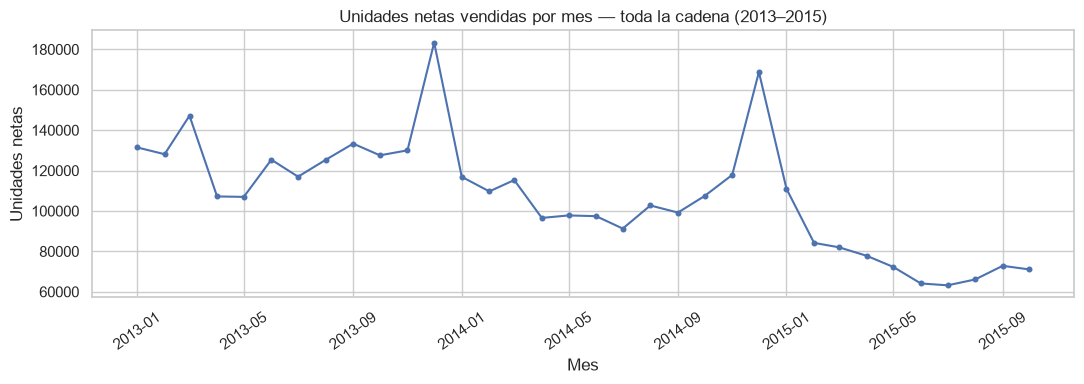

Mayor y menor mes por unidades netas:


,periodo,unidades_netas,ingresos_netos,registros
11,2013-12-01,183342,2.075717e+08,143246
30,2015-07-01,63187,5.940579e+07,55549


In [24]:
# La serie temporal total (unidades e ingresos) permite ver el contexto global.
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(ventas_mes["periodo"], ventas_mes["unidades_netas"], marker="o", ms=3.3)
ax.set(title="Unidades netas vendidas por mes — toda la cadena (2013–2015)",
       xlabel="Mes", ylabel="Unidades netas")
ax.tick_params(axis="x", rotation=35)
plt.tight_layout()
plt.show()
print("Mayor y menor mes por unidades netas:")
display(ventas_mes.loc[[ventas_mes.unidades_netas.idxmax(), ventas_mes.unidades_netas.idxmin()]])

**Interpretación:** La evolución muestra una reducción del nivel general de unidades conforme avanza el horizonte, con **picos estacionales al final de cada año**. El mes de mayor venta fue **diciembre de 2013 (183,342 unidades)**, y el menor fue **julio de 2015 (63,187)**. Esta figura ofrece una vista exploratoria; Mario elaborará las visualizaciones obligatorias de la sección 8 sobre la misma información, reutilizando `ventas_por_periodo`.

### 6.b.i Tendencia

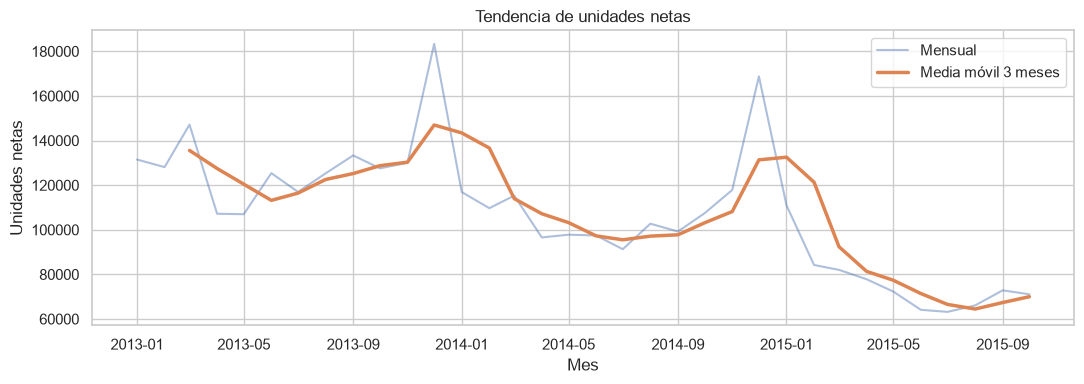

Comparación homogénea: enero-octubre de cada año


,anio,unidades_netas,ingresos_netos,variacion_unidades_pct
0,2013,1249381,8.712893e+08,NaN
1,2014,1034285,9.627117e+08,-17.22
2,2015,764584,8.346231e+08,-26.08


In [25]:
# Tendencia suavizada de 3 meses y comparación de enero-octubre entre años completos/parciales.
serie_tendencia = ventas_mes.copy()
serie_tendencia["media_movil_3m"] = serie_tendencia["unidades_netas"].rolling(3, min_periods=3).mean()
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(serie_tendencia.periodo, serie_tendencia.unidades_netas, alpha=.45, label="Mensual")
ax.plot(serie_tendencia.periodo, serie_tendencia.media_movil_3m, lw=2.5, label="Media móvil 3 meses")
ax.set(title="Tendencia de unidades netas", xlabel="Mes", ylabel="Unidades netas")
ax.legend()
plt.tight_layout()
plt.show()
comp_ene_oct = ventas_mes.loc[ventas_mes.periodo.dt.month <= 10].copy()
comp_ene_oct["anio"] = comp_ene_oct.periodo.dt.year
comp_ene_oct = comp_ene_oct.groupby("anio", as_index=False)[["unidades_netas", "ingresos_netos"]].sum()
comp_ene_oct["variacion_unidades_pct"] = comp_ene_oct.unidades_netas.pct_change() * 100
print("Comparación homogénea: enero-octubre de cada año")
display(comp_ene_oct.round(2))

**Interpretación:** La media móvil de tres meses reduce las oscilaciones de corto plazo y sugiere una **tendencia descendente** en unidades. En meses equivalentes (**enero–octubre**) las ventas pasan de **1,249,381 unidades en 2013** a **1,034,285 en 2014** y **764,584 en 2015**. Los ingresos no siguen necesariamente la misma caída, lo que puede reflejar cambios de precios o mezcla de productos; el EDA **no establece causalidad**. Este descenso debe considerarse al construir las series de forecasting.

### 6.b.ii Estacionalidad

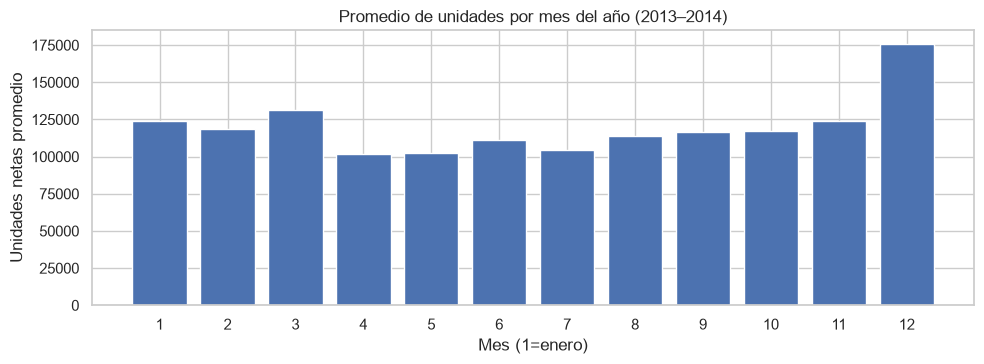

Meses del año ordenados por promedio (años completos 2013 y 2014):


,mes_num,unidades_netas
11,12,176048.0
2,3,131219.0
0,1,124188.0
10,11,123927.0
1,2,118888.0
9,10,117482.0
8,9,116270.0
7,8,114006.0
5,6,111405.0
6,7,104122.0


In [26]:
# Estacionalidad: usar años completos 2013 y 2014, pues 2015 no tiene nov/dic.
mes_estacional = ventas_mes.loc[ventas_mes.periodo.dt.year.isin([2013, 2014])].copy()
mes_estacional["mes_num"] = mes_estacional.periodo.dt.month
estacionalidad = mes_estacional.groupby("mes_num", as_index=False)["unidades_netas"].mean()
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(estacionalidad.mes_num, estacionalidad.unidades_netas)
ax.set(title="Promedio de unidades por mes del año (2013–2014)",
       xlabel="Mes (1=enero)", ylabel="Unidades netas promedio", xticks=range(1, 13))
plt.tight_layout()
plt.show()
print("Meses del año ordenados por promedio (años completos 2013 y 2014):")
display(estacionalidad.sort_values("unidades_netas", ascending=False).round(0))

**Interpretación:** **Diciembre** registra el promedio más alto en los años completos **2013 y 2014: 176,048 unidades**, muy superior al resto de los meses. La repetición en dos diciembres sugiere un componente estacional de fin de año, pero **dos ciclos anuales completos no bastan para demostrar una estacionalidad estable** ni para atribuirla a promociones o festividades concretas. Noviembre y diciembre de 2015 no existen en el entrenamiento; no se imputan como cero.

### 6.b.iii Picos o caídas abruptas

In [27]:
# Variación mensual porcentual; útil para señalar meses que merecen investigación.
cambios_mes = ventas_mes[["periodo", "unidades_netas", "ingresos_netos"]].copy()
cambios_mes["cambio_unidades_pct"] = cambios_mes.unidades_netas.pct_change() * 100
print("5 mayores incrementos mensuales (unidades):")
display(cambios_mes.nlargest(5, "cambio_unidades_pct").round(2))
print("5 mayores caídas mensuales (unidades):")
display(cambios_mes.nsmallest(5, "cambio_unidades_pct").round(2))

5 mayores incrementos mensuales (unidades):


,periodo,unidades_netas,ingresos_netos,cambio_unidades_pct
23,2014-12-01,168754,2.320247e+08,43.20
11,2013-12-01,183342,2.075717e+08,41.02
5,2013-06-01,125381,7.955041e+07,17.21
2,2013-03-01,147142,1.049327e+08,14.87
19,2014-08-01,102721,8.960409e+07,12.54


5 mayores caídas mensuales (unidades):


,periodo,unidades_netas,ingresos_netos,cambio_unidades_pct
12,2014-01-01,116899,9.822602e+07,-36.24
24,2015-01-01,110971,1.189277e+08,-34.24
3,2013-04-01,107190,6.915429e+07,-27.15
25,2015-02-01,84198,8.659388e+07,-24.13
15,2014-04-01,96556,8.065176e+07,-16.25


**Interpretación:** El incremento mensual más alto ocurrió en **diciembre de 2014 (+43.20 % respecto de noviembre)**, y la caída más fuerte en **enero de 2014 (−36.24 % respecto de diciembre de 2013)**. Este patrón es coherente con el repunte de diciembre observado en la sección 6.b.ii. Un salto porcentual, por sí solo, **no prueba un error ni una promoción**: debe contrastarse con el calendario, tipo de producto y tiendas antes de decidir una corrección.

### 6.b.iv Ciclos por día de la semana y mes del año

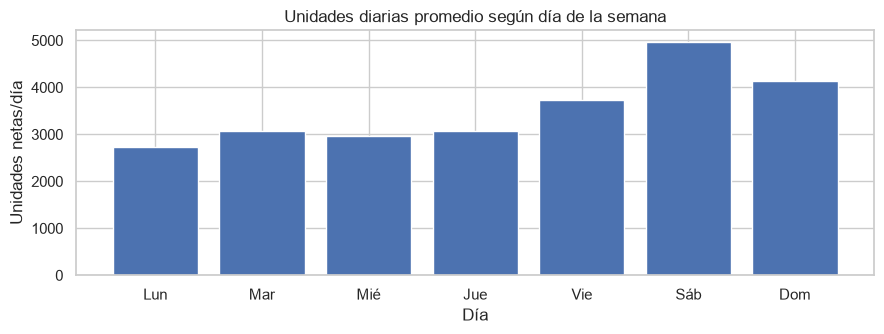

Promedios por día de la semana:


,dia,unidades_netas
0,Lun,2731.2
1,Mar,3074.2
2,Mié,2971.0
3,Jue,3071.8
4,Vie,3739.6
5,Sáb,4963.8
6,Dom,4144.8


Resumen mensual por mes del año (2013 y 2014):


,mes_num,unidades_netas
0,1,124188.0
1,2,118888.0
2,3,131219.0
3,4,101873.0
4,5,102380.0
5,6,111405.0
6,7,104122.0
7,8,114006.0
8,9,116270.0
9,10,117482.0


In [28]:
# Ciclo semanal: promedios por día observado, para no confundir sumas con cantidad de días.
dias = ventas_dia.copy()
dias["dia_semana"] = dias.periodo.dt.dayofweek
promedio_dia = dias.groupby("dia_semana", as_index=False).unidades_netas.mean()
promedio_dia["dia"] = promedio_dia.dia_semana.map({0:"Lun", 1:"Mar", 2:"Mié", 3:"Jue", 4:"Vie", 5:"Sáb", 6:"Dom"})
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.bar(promedio_dia.dia, promedio_dia.unidades_netas)
ax.set(title="Unidades diarias promedio según día de la semana", xlabel="Día", ylabel="Unidades netas/día")
plt.tight_layout()
plt.show()
print("Promedios por día de la semana:")
display(promedio_dia[["dia", "unidades_netas"]].round(1))
print("Resumen mensual por mes del año (2013 y 2014):")
display(estacionalidad.round(0))

**Interpretación:** Las ventas se concentran relativamente en el **fin de semana**: el **sábado** promedia aproximadamente **4,964 unidades**, frente a **2,731 del lunes**. Se usa el **promedio diario** para que un día de la semana no sobresalga solo porque aparezca más veces en el calendario. Por mes del año, diciembre sobresale. Estos patrones son descriptivos y pueden aportar variables de calendario a futuros análisis, aunque la predicción objetivo sea mensual.

## 7. Análisis comparativo entre sucursales y productos

### 7.a Productos y categorías más y menos vendidos

In [29]:
print("Top 10 productos por unidades netas:")
display(resumen_productos.nlargest(10, "unidades_netas")[["item_id", "item_name", "unidades_netas", "ingresos_netos"]])
print("Productos con ventas netas positivas más bajas (no confundir con productos nunca vendidos):")
display(resumen_productos.query("unidades_netas > 0").nsmallest(10, "unidades_netas")[["item_id", "item_name", "unidades_netas"]])
print("Productos con unidades netas <= 0:")
display(resumen_productos.query("unidades_netas <= 0")[["item_id", "item_name", "unidades_netas"]])
print("Top 10 y bottom 10 de categorías por unidades netas:")
display(resumen_categorias.nlargest(10, "unidades_netas")[["item_category_id", "item_category_name", "unidades_netas"]])
display(resumen_categorias.nsmallest(10, "unidades_netas")[["item_category_id", "item_category_name", "unidades_netas"]])

Top 10 productos por unidades netas:


,item_id,item_name,unidades_netas,ingresos_netos
20602,20949,Фирменный пакет майка 1С Интерес белый (34*42)...,187642,9.288637e+05
2749,2808,"Diablo III [PC, Jewel, русская версия]",17245,1.685278e+07
3654,3732,"Grand Theft Auto V [PS3, русские субтитры]",16642,4.361798e+07
17418,17717,Прием денежных средств для 1С-Онлайн,15830,1.720083e+07
5717,5822,Playstation Store пополнение бумажника: Карта ...,14515,1.540898e+07
3656,3734,"Grand Theft Auto V [Xbox 360, русские субтитры]",11688,3.106516e+07
6543,6675,Sony PlayStation 4 (500 Gb) Black (CUH-1008A/1...,10289,2.193915e+08
3653,3731,"Grand Theft Auto V [PC, русские субтитры]",10099,1.998348e+07
1814,1855,"Battlefield 4 [PC, русская версия]",10032,9.357025e+06
16493,16787,"Одни из нас [PS3, русская версия]",9227,2.190784e+07


Productos con ventas netas positivas más bajas (no confundir con productos nunca vendidos):


,item_id,item_name,unidades_netas
0,0,! ВО ВЛАСТИ НАВАЖДЕНИЯ (ПЛАСТ.) D,1
4,4,***КОРОБКА (СТЕКЛО) D,1
5,5,***НОВЫЕ АМЕРИКАНСКИЕ ГРАФФИТИ (UNI) ...,1
6,6,***УДАР ПО ВОРОТАМ (UNI) D,1
7,7,***УДАР ПО ВОРОТАМ-2 (UNI) D,1
9,9,***ШУГАРЛЭНДСКИЙ ЭКСПРЕСС (UNI) D,1
10,10,*ЗА ГРАНЬЮ СМЕРТИ D,1
11,11,*ЛИНИЯ СМЕРТИ D,1
12,12,*МИХЕЙ И ДЖУМАНДЖИ Сука любовь,1
13,13,*СПАСАЯ ЭМИЛИ D,1


Productos con unidades netas <= 0:


,item_id,item_name,unidades_netas
1552,1590,"Assassin’s Creed 3. Freedom Edition [PC, русск...",-11
4504,4591,"MCCARTNEY, PAUL In Red Square (Фирм.)",0
7401,7547,VideoStudio Pro X6 IE Windows Mini-Box,0
8350,8515,Английский язык. 2 - 5 класс (Jewel),0
11664,11871,Змея,-1
13223,13474,Комплект «Sony PS3 (320 Gb) (CECH-2508B) + игр...,-1
13226,13477,Комплект «Sony PS3 (320 Gb) (CECH-3008B)» + иг...,0
17760,18062,Робопет Собака,-1


Top 10 y bottom 10 de categorías por unidades netas:


,item_category_id,item_category_name,unidades_netas
40,40,Кино - DVD,634170
30,30,Игры PC - Стандартные издания,456540
55,55,Музыка - CD локального производства,348591
19,19,Игры - PS3,254887
37,37,Кино - Blu-Ray,203283
71,71,"Подарки - Сумки, Альбомы, Коврики д/мыши",187998
28,28,Игры PC - Дополнительные издания,174954
23,23,Игры - XBOX 360,169940
20,20,Игры - PS4,127319
65,65,Подарки - Настольные игры (компактные),73077


,item_category_id,item_category_name,unidades_netas
10,10,Игровые консоли - PS2,1
51,51,Книги - Познавательная литература,1
1,1,Аксессуары - PS2,2
0,0,PC - Гарнитуры/Наушники,3
50,50,Книги - Открытки,3
52,52,Книги - Путеводители,3
53,53,Книги - Художественная литература,3
48,48,Книги - Компьютерная литература,6
27,27,Игры MAC - Цифра,8
18,18,Игры - PS2,11


**Interpretación:** El producto `20949` lidera en unidades netas (187,642), pero su contribución monetaria es limitada. En categorías, **DVD (40)** lidera con **634,170 unidades**; entre las categorías con ventas históricas, **consolas PS2 (10)** y **libros de literatura educativa (51)** registran solo **1 unidad neta** cada una. Existen productos con ventas netas **cero o negativas** por efecto de devoluciones, por lo que el ranking inferior debe diferenciar ventas mínimas positivas de saldos netos no positivos. Los artículos **sin ninguna venta** no aparecen en `sales_train` y no pueden identificarse únicamente con este ranking histórico; deben cruzarse con el catálogo si se desea estudiarlos.

### 7.b Desempeño entre sucursales

In [30]:
# Normalizar por número de meses CON REGISTROS, pues las tiendas operaron distinto tiempo.
meses_tienda = ventas_mensuales_por(ventas_eda, "shop_id").groupby("shop_id", as_index=False).agg(
    meses_con_registros=("date_block_num", "nunique")
)
comparacion_tiendas = resumen_tiendas.merge(meses_tienda, on="shop_id", validate="one_to_one")
comparacion_tiendas["unidades_por_mes_con_registros"] = (
    comparacion_tiendas.unidades_netas / comparacion_tiendas.meses_con_registros
)
print("Top 10 según unidades totales:")
display(comparacion_tiendas.nlargest(10, "unidades_netas")[["shop_id", "shop_name", "meses_con_registros", "unidades_netas", "unidades_por_mes_con_registros"]].round(1))
print("Top 10 según unidades por mes (solo tiendas con >= 12 meses registrados):")
display(comparacion_tiendas.query("meses_con_registros >= 12").nlargest(10, "unidades_por_mes_con_registros")[["shop_id", "shop_name", "meses_con_registros", "unidades_por_mes_con_registros"]].round(1))
print("Tiendas con menor volumen total y cobertura temporal:")
display(comparacion_tiendas.nsmallest(8, "unidades_netas")[["shop_id", "shop_name", "meses_con_registros", "unidades_netas"]])

Top 10 según unidades totales:


,shop_id,shop_name,meses_con_registros,unidades_netas,unidades_por_mes_con_registros
28,31,"Москва ТЦ ""Семеновский""",34,310777,9140.5
22,25,"Москва ТРК ""Атриум""",34,241919,7115.3
51,54,"Химки ТЦ ""Мега""",28,185789,6635.3
25,28,"Москва ТЦ ""МЕГА Теплый Стан"" II",34,184557,5428.1
54,57,"Якутск Орджоникидзе, 56",34,152812,4494.5
39,42,"СПб ТК ""Невский Центр""",34,144933,4262.7
24,27,"Москва ТЦ ""МЕГА Белая Дача II""",32,136657,4270.5
4,6,"Воронеж (Плехановская, 13)",34,100489,2955.6
55,58,"Якутск ТЦ ""Центральный""",34,88045,2589.6
43,46,"Сергиев Посад ТЦ ""7Я""",34,78990,2323.2


Top 10 según unidades por mes (solo tiendas con >= 12 meses registrados):


,shop_id,shop_name,meses_con_registros,unidades_por_mes_con_registros
28,31,"Москва ТЦ ""Семеновский""",34,9140.5
22,25,"Москва ТРК ""Атриум""",34,7115.3
51,54,"Химки ТЦ ""Мега""",28,6635.3
25,28,"Москва ТЦ ""МЕГА Теплый Стан"" II",34,5428.1
54,57,"Якутск Орджоникидзе, 56",34,4494.5
24,27,"Москва ТЦ ""МЕГА Белая Дача II""",32,4270.5
39,42,"СПб ТК ""Невский Центр""",34,4262.7
4,6,"Воронеж (Плехановская, 13)",34,2955.6
55,58,"Якутск ТЦ ""Центральный""",34,2589.6
27,30,"Москва ТЦ ""Перловский""",26,2339.5


Tiendas con menor volumen total y cobertura temporal:


,shop_id,shop_name,meses_con_registros,unidades_netas
33,36,"Новосибирск ТРЦ ""Галерея Новосибирск""",1,330
6,8,"Воронеж ТРЦ Сити-Парк ""Град""",4,3595
37,40,"РостовНаДону ТРК ""Мегацентр Горизонт"" Островной",11,4943
30,33,"Мытищи ТРК ""XL-3""",9,5482
17,20,"Москва ""Распродажа""",2,5872
31,34,"Н.Новгород ТРЦ ""РИО""",16,6451
20,23,"Москва ТК ""Буденовский"" (пав.А2)",4,7705
29,32,"Москва ТЦ ""Серебряный Дом""",7,8781


**Interpretación:** La tienda **31** mantiene el liderazgo tanto en volumen acumulado (**310,777 unidades**) como entre tiendas con al menos 12 meses registrados (**≈9,141 unidades por mes con registros**). La tienda **36** registra apenas **330 unidades**, pero solo tiene **1 mes con ventas**, por lo que sería incorrecto considerarla directamente la menos productiva de la cadena. El indicador `unidades_por_mes_con_registros` **no equivale a productividad por mes de apertura real**, porque Kaggle no informa fechas oficiales de operación y no contabiliza meses sin registros; se presenta como medida descriptiva de comparabilidad.

### 7.c Outliers y comportamientos anómalos

In [31]:
# Diagnóstico de casos extremos sin eliminar observaciones.
cuantiles = ventas_eda[["item_price", "item_cnt_day", "ingresos"]].quantile([.5, .99, .999, .9999])
print("Cuantiles para detectar colas extremas:")
display(cuantiles.round(2))
q_precio = float(ventas_eda.item_price.quantile(.999))
q_unidades = float(ventas_eda.item_cnt_day.quantile(.999))
print(f"Registros por encima del percentil 99.9 de precio: {(ventas_eda.item_price > q_precio).sum():,} (umbral {q_precio:,.2f})")
print(f"Registros por encima del percentil 99.9 de cantidad: {(ventas_eda.item_cnt_day > q_unidades).sum():,} (umbral {q_unidades:,.0f})")
print("Transacciones con mayores cantidades:")
display(ventas_eda.nlargest(10, "item_cnt_day")[["date", "shop_id", "item_id", "item_price", "item_cnt_day", "ingresos"]].round(2))
print("Transacciones con mayores precios unitarios:")
display(ventas_eda.nlargest(10, "item_price")[["date", "shop_id", "item_id", "item_price", "item_cnt_day"]].round(2))
# Concentración de extremos por tienda, solo para revisar; no eliminar sin fundamento.
alertas = ventas_eda.loc[(ventas_eda.item_price > q_precio) | (ventas_eda.item_cnt_day > q_unidades)]
print("Tiendas con más registros que superan alguno de los dos umbrales:")
display(alertas.groupby("shop_id").size().sort_values(ascending=False).head(10).rename("registros_en_revision").to_frame())

Cuantiles para detectar colas extremas:


,item_price,item_cnt_day,ingresos
0.5000,399.0,1.0,449.00
0.9900,5999.0,5.0,11375.00
0.9990,23990.0,22.0,45487.16
0.9999,29990.0,67.0,186766.42


Registros por encima del percentil 99.9 de precio: 2,932 (umbral 23,990.00)
Registros por encima del percentil 99.9 de cantidad: 2,882 (umbral 22)
Transacciones con mayores cantidades:


,date,shop_id,item_id,item_price,item_cnt_day,ingresos
2909812,2015-10-28,12,11373,0.91,2169,1971.0
2326924,2015-01-15,12,20949,4.00,1000,4000.0
2864229,2015-09-30,12,9248,1692.53,669,1132300.0
2851085,2015-09-30,55,9249,1702.83,637,1084700.0
2608034,2015-04-14,12,3731,1904.55,624,1188438.0
2626175,2015-05-19,12,11373,155.19,539,83649.0
2851067,2015-09-29,55,9249,1500.00,533,799500.0
2048513,2014-10-02,12,9242,1500.00,512,768000.0
2067664,2014-10-09,55,19437,899.00,508,456692.0
2864254,2015-09-29,12,9248,1500.00,504,756000.0


Transacciones con mayores precios unitarios:


,date,shop_id,item_id,item_price,item_cnt_day
1163157,2013-12-13,12,6066,307980.0,1
885137,2013-09-17,12,11365,59200.0,1
1488133,2014-03-20,25,13199,50999.0,1
2327153,2015-01-29,12,7241,49782.0,1
2885686,2015-10-23,42,13403,42990.0,1
2910150,2015-10-29,12,13403,42990.0,1
2917754,2015-10-20,3,13403,42990.0,1
2931374,2015-10-20,22,13403,42990.0,1
1006637,2013-10-24,12,7238,42000.0,1
2893094,2015-10-20,38,13403,41990.0,1


Tiendas con más registros que superan alguno de los dos umbrales:


,registros_en_revision
shop_id,
31,643
25,478
12,423
28,328
54,313
42,296
27,226
55,170
6,160


**Interpretación:** La mediana de la cantidad por transacción es **1**, pero hay registros de hasta **2,169 unidades**; el percentil **99.9** es **22 unidades**. En precio, la mediana es **399** y el percentil 99.9 es **23,990**, con un máximo de **307,980**. Estos valores extremos pueden obedecer a operaciones mayoristas, artículos caros, registros especiales o errores que requieren revisión adicional; **no corresponde eliminarlos automáticamente**. Se mantienen en el EDA siguiendo la política del equipo, y quedan identificados para evaluar transformaciones o límites solo durante el modelado.

## 8. Visualizaciones clave (obligatorias)

### 8.a Serie de tiempo de ventas totales

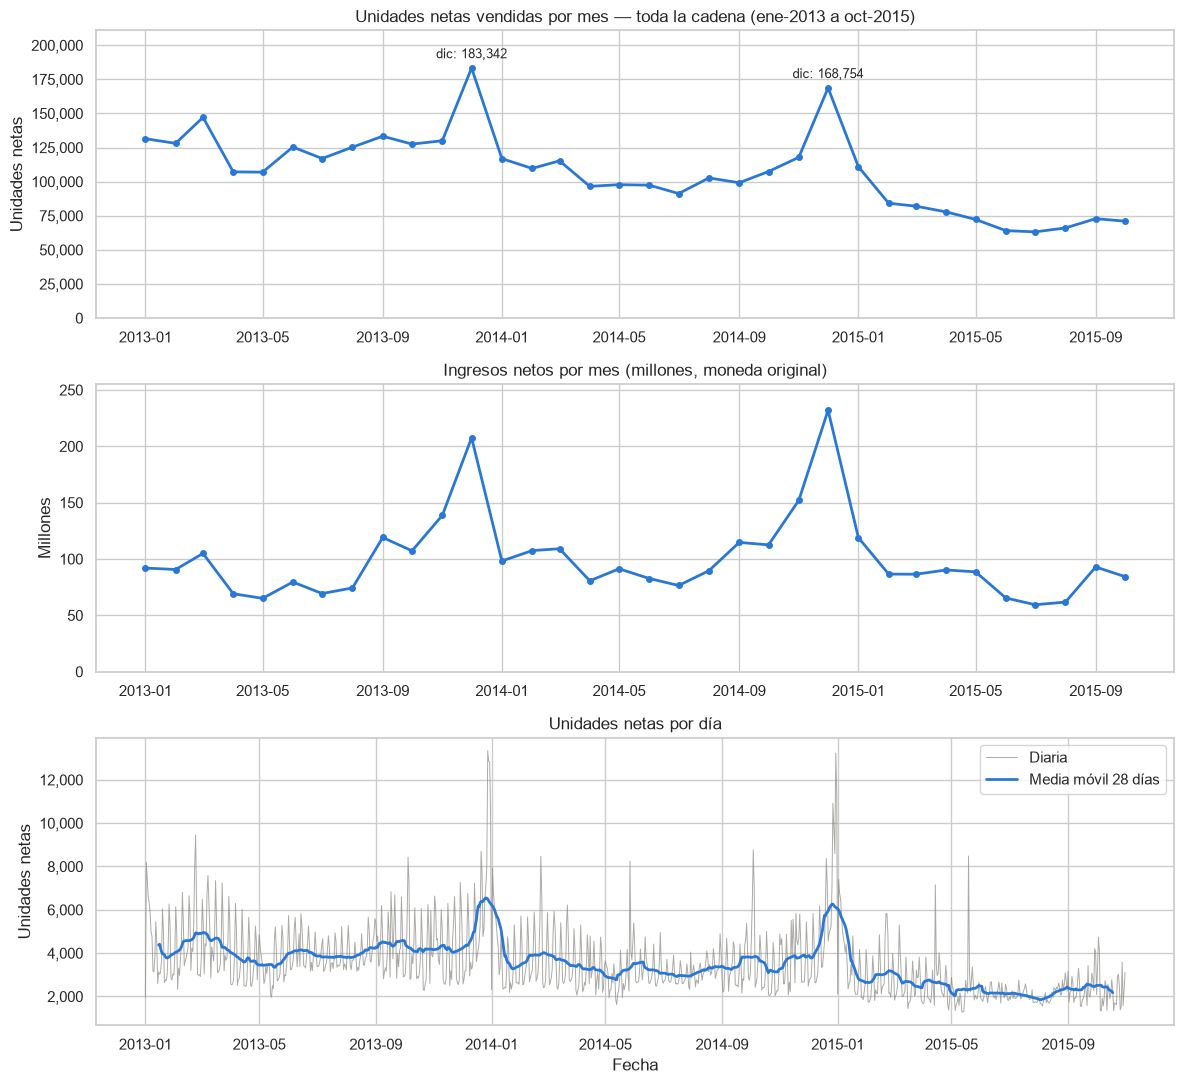

Tendencia lineal de unidades: -1,944 unidades por mes
Correlación mensual unidades vs. ingresos: 0.72
Ingreso medio por unidad (ingresos / unidades) en el primer y último año:


,ingreso_por_unidad
anio,
2013,779.1
2014,1019.6
2015,1091.6


5 días con más unidades netas:


,periodo,unidades_netas,registros
361,2013-12-28,13343,9434
728,2014-12-30,13236,9324
362,2013-12-29,12863,9335
363,2013-12-30,12823,9138
729,2014-12-31,11393,8346


In [32]:
# Bloque 3 (Mario): funciones reutilizables de las secciones 8, 9 y 10.
from predict_future_sales.features import (
    agregar_grupo_categoria, cobertura_test, matriz_mensual, resumen_autocorrelacion,
)
from predict_future_sales.plots import (
    COLOR_NEUTRO, COLOR_PRINCIPAL, COLOR_SECUNDARIO, MAPA_SECUENCIAL,
    barras_horizontales, etiqueta_mes, formato_miles, graficar_acf_pacf, guardar_figura,
)
from matplotlib.patches import Patch

# 8.a Serie de tiempo de ventas totales: mensual (frecuencia del objetivo) y diaria (contexto).
fig, axes = plt.subplots(3, 1, figsize=(12, 11))

ax = axes[0]
ax.plot(ventas_mes.periodo, ventas_mes.unidades_netas, marker="o", ms=4, lw=2, color=COLOR_PRINCIPAL)
for _, fila in ventas_mes.loc[ventas_mes.periodo.dt.month == 12].iterrows():
    ax.annotate(f"dic: {fila.unidades_netas:,.0f}", (fila.periodo, fila.unidades_netas),
                textcoords="offset points", xytext=(0, 7), ha="center", fontsize=9)
ax.set(title="Unidades netas vendidas por mes — toda la cadena (ene-2013 a oct-2015)", ylabel="Unidades netas")
ax.set_ylim(0, ventas_mes.unidades_netas.max() * 1.15)
formato_miles(ax)

ax = axes[1]
ax.plot(ventas_mes.periodo, ventas_mes.ingresos_netos / 1e6, marker="o", ms=4, lw=2, color=COLOR_PRINCIPAL)
ax.set(title="Ingresos netos por mes (millones, moneda original)", ylabel="Millones")
ax.set_ylim(0, ventas_mes.ingresos_netos.max() / 1e6 * 1.1)

ax = axes[2]
ax.plot(ventas_dia.periodo, ventas_dia.unidades_netas, lw=0.7, color=COLOR_NEUTRO, alpha=0.7, label="Diaria")
ax.plot(ventas_dia.periodo, ventas_dia.unidades_netas.rolling(28, center=True).mean(),
        lw=2, color=COLOR_PRINCIPAL, label="Media móvil 28 días")
ax.set(title="Unidades netas por día", ylabel="Unidades netas", xlabel="Fecha")
ax.legend(loc="upper right")
formato_miles(ax)

plt.tight_layout()
guardar_figura(fig, "8a_serie_ventas_totales")
plt.show()

pendiente = np.polyfit(np.arange(len(ventas_mes)), ventas_mes.unidades_netas, 1)[0]
print(f"Tendencia lineal de unidades: {pendiente:,.0f} unidades por mes")
print(f"Correlación mensual unidades vs. ingresos: {ventas_mes.unidades_netas.corr(ventas_mes.ingresos_netos):.2f}")
print("Ingreso medio por unidad (ingresos / unidades) en el primer y último año:")
ticket = ventas_mes.assign(anio=ventas_mes.periodo.dt.year).groupby("anio")[["ingresos_netos", "unidades_netas"]].sum()
display((ticket.ingresos_netos / ticket.unidades_netas).rename("ingreso_por_unidad").round(1).to_frame())
print("5 días con más unidades netas:")
display(ventas_dia.nlargest(5, "unidades_netas")[["periodo", "unidades_netas", "registros"]])

**Interpretación:**
- **Tendencia descendente en unidades:** la cadena pasa de ~130 mil unidades al mes en 2013 a ~70 mil en 2015. La recta de tendencia cae **~1,944 unidades por mes**.
- **Picos de diciembre:** **183,342 unidades en dic-2013** y **168,754 en dic-2014**, seguidos de una caída fuerte en enero. En la serie diaria los días con más ventas son el **28-dic-2013 (13,343)** y el **30-dic-2014 (13,236)**.
- **Los ingresos no caen al mismo ritmo** (correlación mensual unidades-ingresos de 0.72). El ingreso por unidad sube de **779 (2013)** a **1,020 (2014)** y **1,092 (2015)**. Dic-2014 tiene **más ingresos que dic-2013 con menos unidades**, lo que es coherente con una mezcla hacia productos más caros (consolas y juegos de PS4, ver 8.c), pero el EDA no prueba la causa.
- **Ciclo semanal en la serie diaria:** el patrón en dientes de sierra es el ciclo semanal que se mide en 9.1. La media móvil de 28 días lo suaviza y deja ver la tendencia y los picos de fin de año.
- **Implicación:** la serie mensual **no es estacionaria en nivel** (tiene tendencia). Un modelo debe capturar la tendencia y el efecto de fin de año, o trabajar con diferencias.

### 8.b Barras: ventas por sucursal

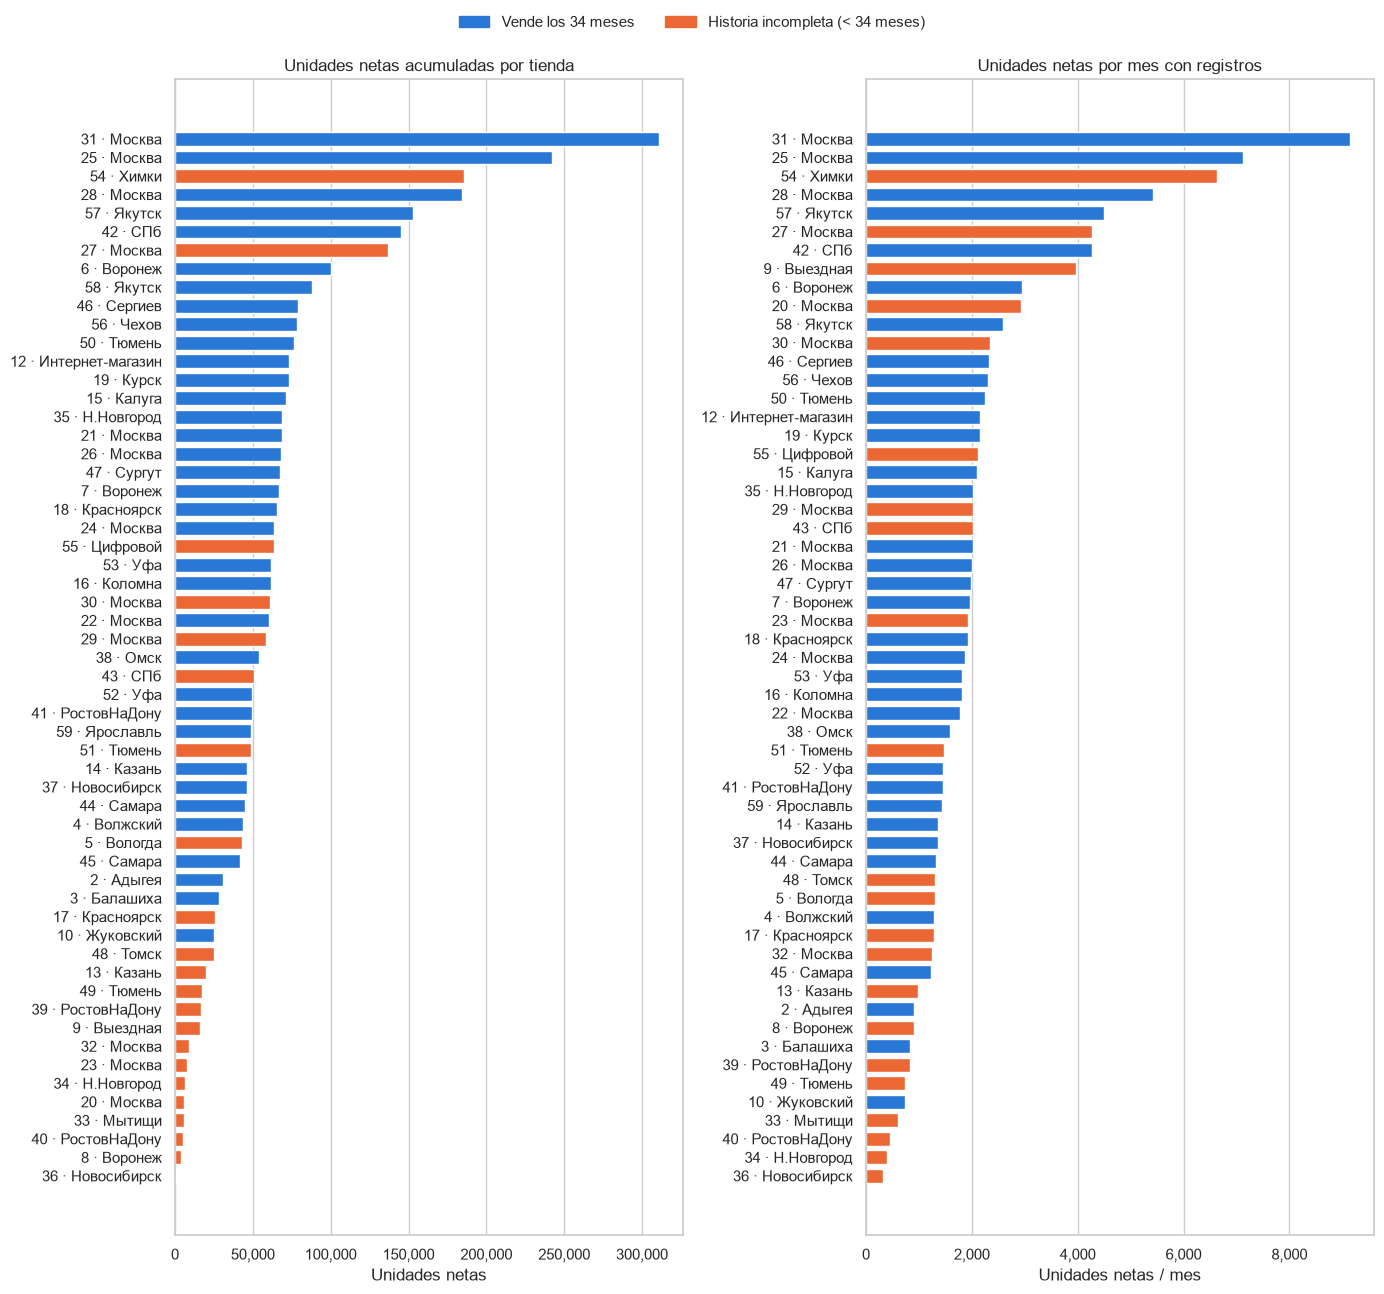

Tiendas con historia incompleta: 22 de 57
Participación de las 5 mayores tiendas: 29.5% de las unidades
Tiendas necesarias para acumular el 50% de las unidades: 13
Razón tienda mayor / mediana (unidades acumuladas): 5.8x


In [33]:
# 8.b Ventas por sucursal: acumulado y promedio por mes con registros (de 7.b).
tiendas_graf = comparacion_tiendas.copy()
tiendas_graf["ciudad"] = tiendas_graf.shop_name.str.lstrip("!").str.split().str[0]
tiendas_graf["etiqueta"] = tiendas_graf.shop_id.astype(str) + " · " + tiendas_graf.ciudad
tiendas_graf["historia_incompleta"] = tiendas_graf.meses_con_registros < 34

fig, axes = plt.subplots(1, 2, figsize=(14, 13))
orden = tiendas_graf.sort_values("unidades_netas", ascending=False)
barras_horizontales(axes[0], orden.etiqueta, orden.unidades_netas,
                    "Unidades netas acumuladas por tienda", "Unidades netas",
                    resaltar=orden.historia_incompleta)
orden = tiendas_graf.sort_values("unidades_por_mes_con_registros", ascending=False)
barras_horizontales(axes[1], orden.etiqueta, orden.unidades_por_mes_con_registros,
                    "Unidades netas por mes con registros", "Unidades netas / mes",
                    resaltar=orden.historia_incompleta)
leyenda = [Patch(color=COLOR_PRINCIPAL, label="Vende los 34 meses"),
           Patch(color=COLOR_SECUNDARIO, label="Historia incompleta (< 34 meses)")]
plt.tight_layout(rect=(0, 0, 1, 0.97))
fig.legend(handles=leyenda, loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.0), frameon=False)
guardar_figura(fig, "8b_ventas_por_sucursal")
plt.show()

participacion = orden.sort_values("unidades_netas", ascending=False).participacion_unidades_pct.cumsum()
print(f"Tiendas con historia incompleta: {tiendas_graf.historia_incompleta.sum()} de {len(tiendas_graf)}")
print(f"Participación de las 5 mayores tiendas: {participacion.iloc[4]:.1f}% de las unidades")
print(f"Tiendas necesarias para acumular el 50% de las unidades: {(participacion < 50).sum() + 1}")
print(f"Razón tienda mayor / mediana (unidades acumuladas): "
      f"{tiendas_graf.unidades_netas.max() / tiendas_graf.unidades_netas.median():.1f}x")

**Interpretación:**
- **Ventas concentradas:** las **5 mayores tiendas suman 29.5 %** de las unidades y bastan **13 de 57** para llegar al 50 %. La tienda mayor (**31, Moscú**) vende **5.8 veces** lo que la tienda mediana. Moscú domina el top.
- **22 de 57 tiendas (naranja) tienen historia incompleta,** y eso distorsiona el acumulado.
  - Al normalizar por meses con registros, la **54 (Химки)** sube al 3.er lugar (≈6,600 unidades/mes), pero **dejó de vender en abr-2015**.
  - La **9** (venta itinerante) y la **20** (liquidación) aparecen altas por mes porque solo venden en pocos meses de evento.
  - La **36** tiene un solo mes (oct-2015).
- **Tiendas especiales:** la **12** (tienda en línea) y la **55** (tienda digital) se comportan distinto a las físicas (ver 8.d).
- **Implicación para el modelo:** el nivel de cada tienda es muy distinto, así que el identificador de tienda (o su nivel histórico) es una variable relevante. Las tiendas cerradas o de evento no deben pesar igual que las activas.

### 8.c Barras: ventas por producto (top N) y por categoría

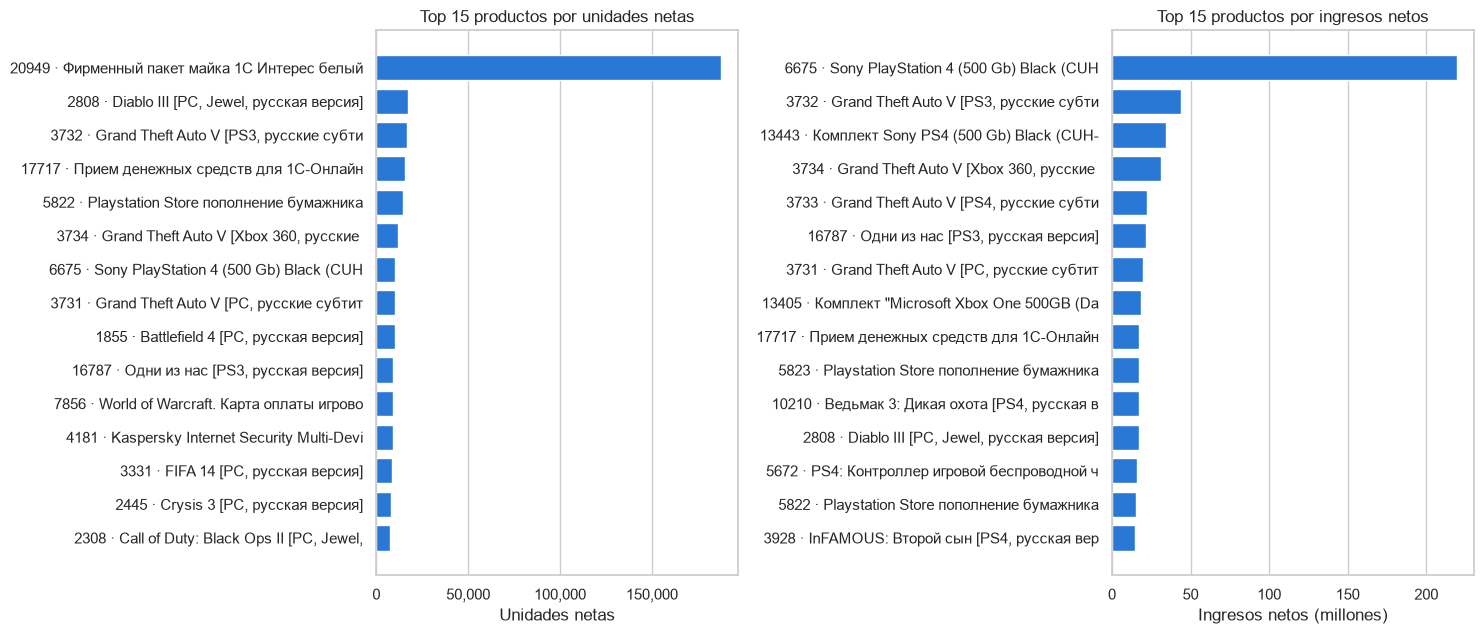

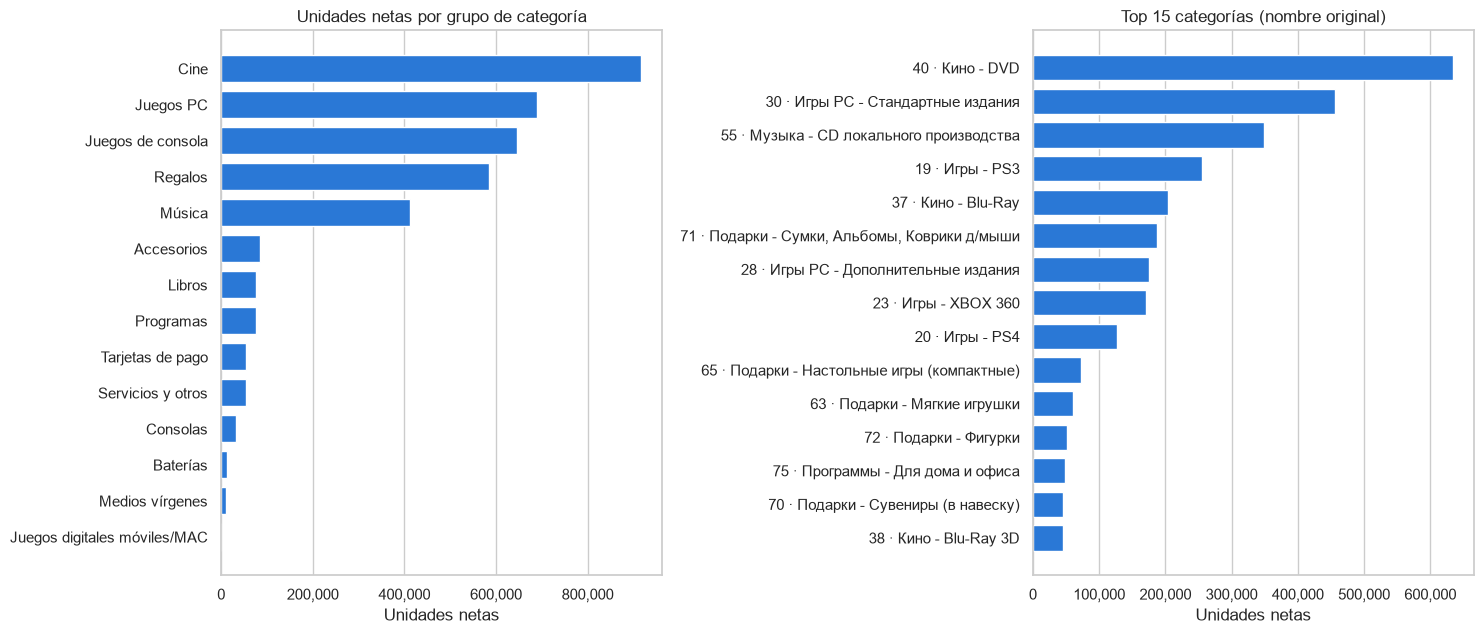

Participación por grupo de categoría (unidades vs. ingresos):


,grupo_categoria,unidades_netas,pct_unidades,ingresos_netos,pct_ingresos
2,Cine,916941,25.1,3.349873e+08,9.9
4,Juegos PC,689098,18.9,4.779817e+08,14.1
5,Juegos de consola,646770,17.7,1.153845e+09,33.9
11,Regalos,584366,16.0,3.091466e+08,9.1
9,Música,411294,11.3,1.497200e+08,4.4
0,Accesorios,85059,2.3,1.663870e+08,4.9
7,Libros,76341,2.1,3.034890e+07,0.9
10,Programas,74954,2.1,1.223909e+08,3.6
13,Tarjetas de pago,53883,1.5,7.295310e+07,2.1
12,Servicios y otros,53783,1.5,5.141043e+07,1.5


Participación del top 15 de productos en las unidades totales: 9.4%


In [34]:
# 8.c Ventas por producto (top 15) y por categoría.
N = 15
categorias_grupo = agregar_grupo_categoria(item_categories)
ventas_cat = (
    ventas_eda.merge(items[["item_id", "item_category_id"]], on="item_id", how="left", validate="many_to_one")
    .merge(categorias_grupo[["item_category_id", "grupo_categoria"]], on="item_category_id",
           how="left", validate="many_to_one")
)
productos_graf = resumen_productos.copy()
productos_graf["etiqueta"] = productos_graf.item_id.astype(str) + " · " + productos_graf.item_name.str.slice(0, 38)

# Productos: unidades e ingresos (los rankings no coinciden)
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
top = productos_graf.nlargest(N, "unidades_netas")
barras_horizontales(axes[0], top.etiqueta, top.unidades_netas, f"Top {N} productos por unidades netas", "Unidades netas")
top = productos_graf.nlargest(N, "ingresos_netos")
barras_horizontales(axes[1], top.etiqueta, top.ingresos_netos / 1e6, f"Top {N} productos por ingresos netos",
                    "Ingresos netos (millones)")
plt.tight_layout()
guardar_figura(fig, "8c_top_productos")
plt.show()

# Categorías: grupos en español (DEC-014) y top 15 categorías originales
grupos = resumen_ventas(ventas_cat, "grupo_categoria")
grupos["pct_unidades"] = 100 * grupos.unidades_netas / grupos.unidades_netas.sum()
grupos["pct_ingresos"] = 100 * grupos.ingresos_netos / grupos.ingresos_netos.sum()
categorias_graf = resumen_categorias.copy()
categorias_graf["etiqueta"] = categorias_graf.item_category_id.astype(str) + " · " + categorias_graf.item_category_name

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
orden = grupos.sort_values("unidades_netas", ascending=False)
barras_horizontales(axes[0], orden.grupo_categoria, orden.unidades_netas,
                    "Unidades netas por grupo de categoría", "Unidades netas")
top = categorias_graf.nlargest(N, "unidades_netas")
barras_horizontales(axes[1], top.etiqueta, top.unidades_netas, f"Top {N} categorías (nombre original)", "Unidades netas")
plt.tight_layout()
guardar_figura(fig, "8c_ventas_por_categoria")
plt.show()

print("Participación por grupo de categoría (unidades vs. ingresos):")
display(grupos.sort_values("unidades_netas", ascending=False)
        [["grupo_categoria", "unidades_netas", "pct_unidades", "ingresos_netos", "pct_ingresos"]].round(1))
print(f"Participación del top {N} de productos en las unidades totales: "
      f"{100 * productos_graf.nlargest(N, 'unidades_netas').unidades_netas.sum() / productos_graf.unidades_netas.sum():.1f}%")

**Interpretación:**
- **Producto 20949 (bolsa de marca 1C):** vende **187,642 unidades**, unas 10 veces más que el segundo producto. No es mercancía (es la bolsa que se entrega con la compra) y su ingreso es mínimo.
- **El resto del top 15 por unidades** son videojuegos de alto perfil (Diablo III, GTA V en varias plataformas, Battlefield 4, FIFA 14), recargas de PlayStation Store y un servicio de cobro (17717).
- **Por ingresos el ranking cambia:** lo lidera la **consola PS4 (6675) con ~219 millones**, seguida de GTA V y paquetes de PS4/Xbox One.
- **Cola larga:** el top 15 de productos es solo el **9.4 %** de las unidades.
- **Por grupo de categoría, unidades e ingresos cuentan historias distintas:**
  - **Cine** es el grupo más vendido (**25.1 % de las unidades**), pero solo genera el **9.9 % de los ingresos**.
  - **Juegos de consola** tienen el 17.7 % de las unidades y el **33.9 % de los ingresos**.
  - **Consolas** son apenas el **0.9 % de las unidades** y el **15.5 % de los ingresos**.
- **Por categoría individual**, la mayor es **DVD (40)**, seguida de juegos de PC estándar (30) y CD de música local (55).
- **Implicación:** la categoría (y su grupo) es una variable clave, porque define el volumen y el precio típico. Para unidades, los grupos dominantes son Cine, Juegos PC, Juegos de consola, Regalos y Música (≈89 % de las unidades).

*Nota:* los grupos de categoría en español son una agrupación del prefijo del nombre ruso, hecha solo para presentar resultados (DEC-014). `item_categories.csv` no se modifica.

### 8.d Heatmap: ventas en el tiempo por sucursal/categoría

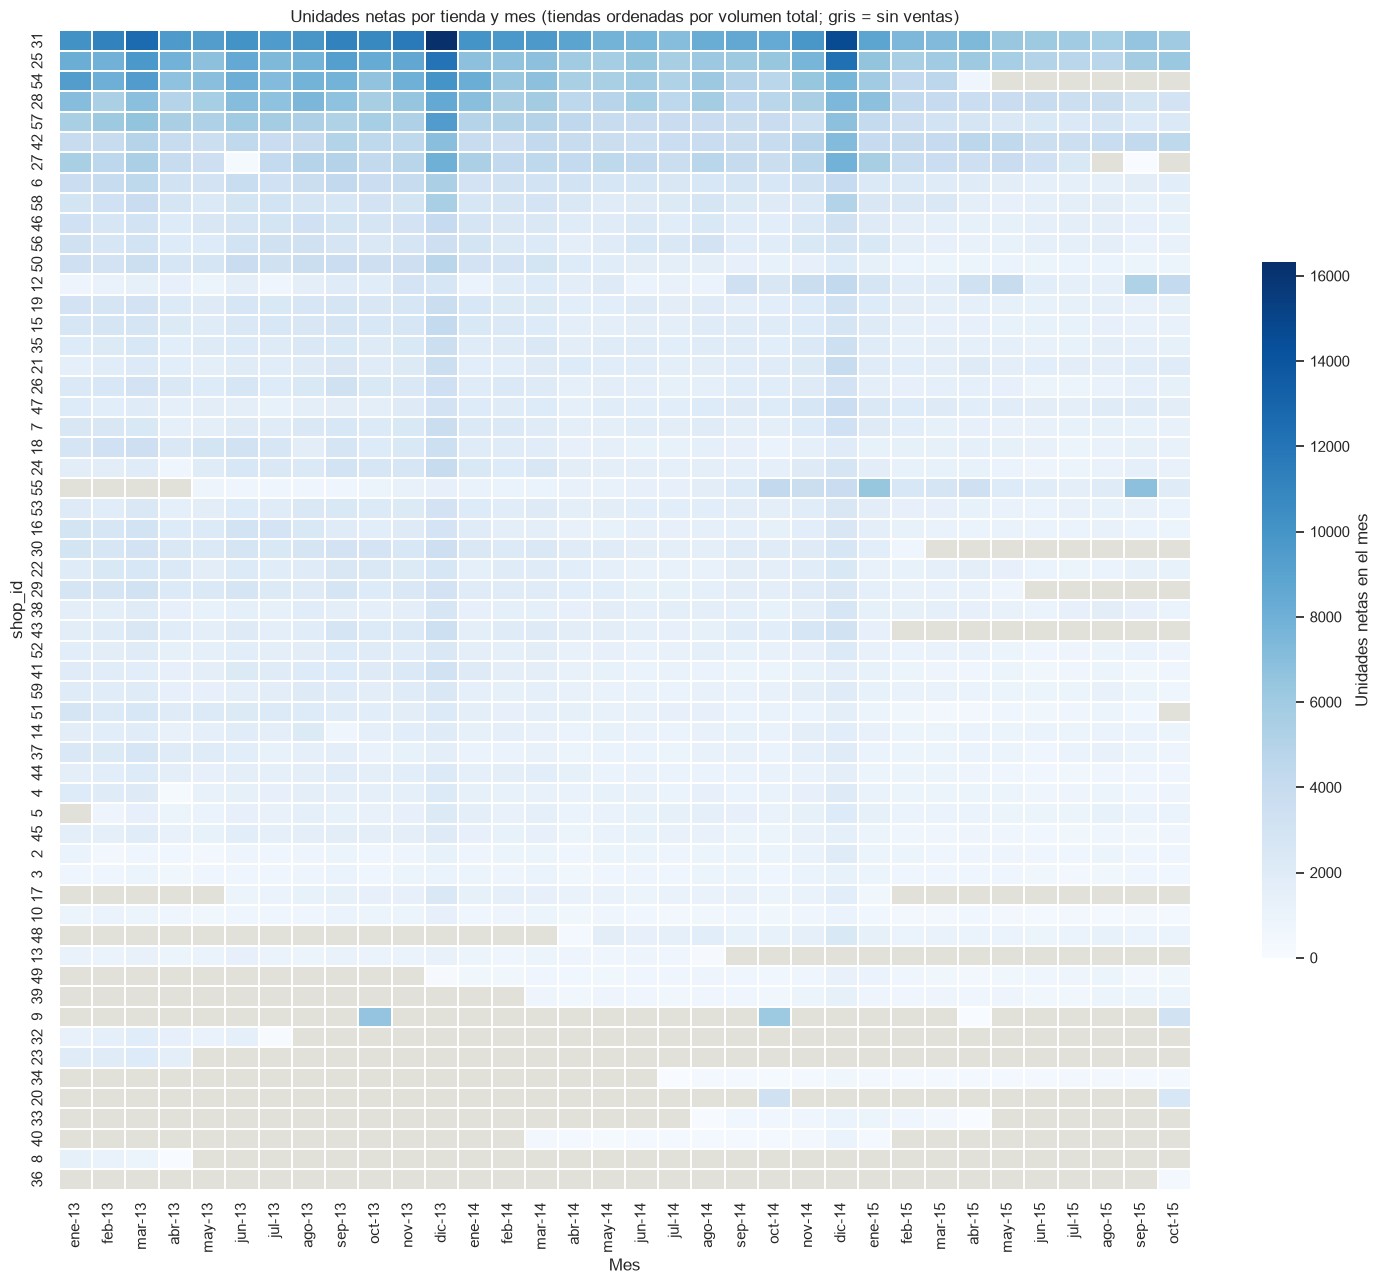

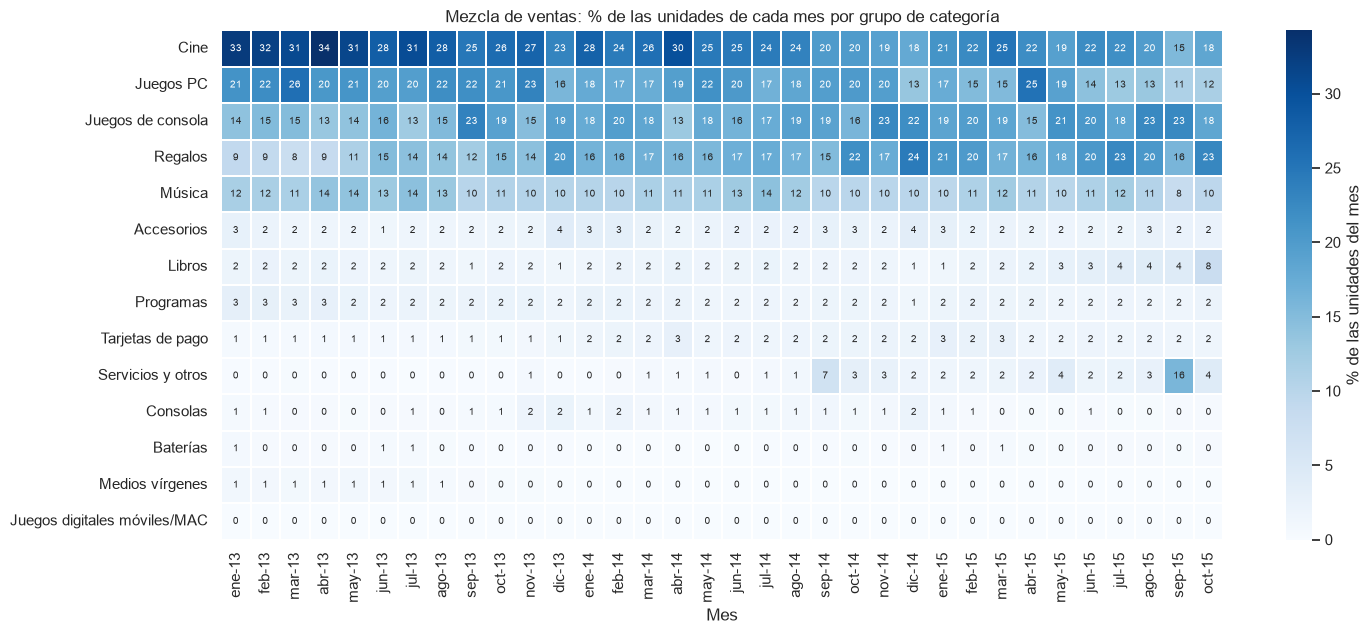

Tiendas con ventas en los 34 meses: 35 de 57
Tiendas con ventas en oct-2015 (mes 33): 44
Cambio en la participación promedio (puntos %), 2013 vs. últimos 12 meses (nov-14 a oct-15):


,cambio_pp
grupo_categoria,
Cine,-8.8
Juegos PC,-5.4
Música,-1.6
Medios vírgenes,-0.7
Programas,-0.6
Consolas,-0.1
Juegos digitales móviles/MAC,0.0
Baterías,0.0
Accesorios,0.3


In [35]:
# 8.d Heatmaps: tienda x mes (unidades) y grupo de categoría x mes (% de las unidades del mes).
meses_etiqueta = [etiqueta_mes(m) for m in range(34)]

mat_tiendas = matriz_mensual(ventas_eda, "shop_id")
mat_tiendas = mat_tiendas.loc[mat_tiendas.sum(axis=1).sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(15, 13))
sns.heatmap(mat_tiendas, cmap=MAPA_SECUENCIAL, ax=ax, linewidths=0.3, linecolor="white",
            mask=(mat_tiendas == 0), cbar_kws={"label": "Unidades netas en el mes", "shrink": 0.6},
            xticklabels=meses_etiqueta, yticklabels=True)
ax.set_facecolor("#e1e0d9")  # gris = mes sin registros
ax.grid(False)
ax.set(title="Unidades netas por tienda y mes (tiendas ordenadas por volumen total; gris = sin ventas)",
       xlabel="Mes", ylabel="shop_id")
ax.tick_params(axis="x", rotation=90)
plt.tight_layout()
guardar_figura(fig, "8d_heatmap_tienda_mes")
plt.show()

mat_grupos = matriz_mensual(ventas_cat, "grupo_categoria")
mat_grupos_pct = 100 * mat_grupos / mat_grupos.sum(axis=0)
mat_grupos_pct = mat_grupos_pct.loc[mat_grupos.sum(axis=1).sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(15, 6.5))
sns.heatmap(mat_grupos_pct, cmap=MAPA_SECUENCIAL, ax=ax, linewidths=0.3, linecolor="white",
            annot=True, fmt=".0f", annot_kws={"fontsize": 7},
            cbar_kws={"label": "% de las unidades del mes"}, xticklabels=meses_etiqueta)
ax.set(title="Mezcla de ventas: % de las unidades de cada mes por grupo de categoría", xlabel="Mes", ylabel="")
ax.tick_params(axis="x", rotation=90)
plt.tight_layout()
guardar_figura(fig, "8d_heatmap_categoria_mes")
plt.show()

activas = (mat_tiendas > 0)
print(f"Tiendas con ventas en los 34 meses: {(activas.sum(axis=1) == 34).sum()} de {len(activas)}")
print(f"Tiendas con ventas en oct-2015 (mes 33): {activas[33].sum()}")
cambio_mezcla = (mat_grupos_pct[list(range(22, 34))].mean(axis=1) - mat_grupos_pct[list(range(0, 12))].mean(axis=1))
print("Cambio en la participación promedio (puntos %), 2013 vs. últimos 12 meses (nov-14 a oct-15):")
display(cambio_mezcla.sort_values().round(1).rename("cambio_pp").to_frame())

**Interpretación:**

**Tienda × mes:**
- **Diciembre se oscurece en casi todas las tiendas.** La estacionalidad de fin de año es compartida por la cadena, no la produce una sola tienda.
- **Las celdas grises muestran aperturas y cierres:**
  - Abren después de ene-2013: 48, 49, 39, 34, 55, entre otras.
  - Dejan de vender: 54 (desde may-2015), 30, 43, 29, 13, 32, 23, 8, entre otras.
- **Solo 35 de 57 tiendas venden los 34 meses** y **44 tienen ventas en oct-2015**.
- **Tiendas de evento:** la **9** (venta itinerante) vende en **oct-2013, oct-2014, abr-2015 y oct-2015**, y la **20** (liquidación) en **oct-2014 y oct-2015**. Son eventos que se repiten en octubre. Ninguna está en `test.csv`.
- **Tienda en línea:** la **12** crece en 2014-2015, a diferencia de la tendencia general.

**Mezcla por grupo de categoría (% de las unidades de cada mes):**
- **Cine pierde 8.8 puntos porcentuales** entre 2013 y los últimos 12 meses (de ~30 % a ~20 %), y **Juegos PC pierde 5.4 puntos**.
- **Ganan participación** Regalos (**+7.1**), Juegos de consola (**+3.9**) y Servicios y otros (**+3.3**; pico de 16 % en sep-2015).
- Libros sube a 8 % en oct-2015.
- **Implicación:** la tendencia total combina la caída de formatos físicos (DVD, juegos de PC) con el crecimiento de otros grupos. Modelar a nivel de categoría captura mejor estos cambios que una sola tendencia global.

## 9. Autocorrelación (ACF) y autocorrelación parcial (PACF)

### 9.1 Ventas totales (mensual y diaria)

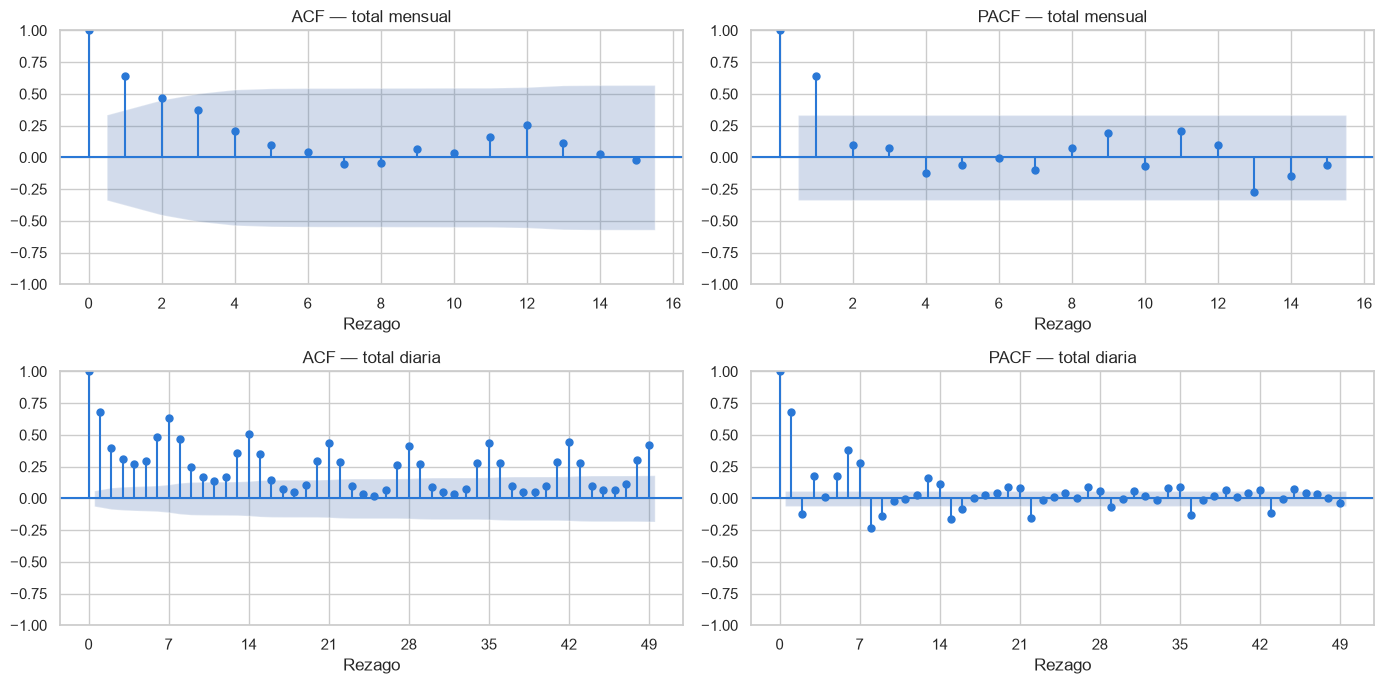

In [36]:
# 9.1 Ventas totales: mensual (34 obs., hasta 15 rezagos) y diaria (1,034 obs., hasta 49 rezagos = 7 semanas).
series_acf = {}  # nombre -> (serie, rezagos, rezago estacional); se resume en 9.5

serie_total_mes = serie_mensual(ventas_eda).set_index("fecha_mes")["unidades_netas"]
serie_total_dia = ventas_dia.set_index("periodo")["unidades_netas"]
series_acf["Total (mensual)"] = (serie_total_mes, 15, 12)
series_acf["Total (diaria)"] = (serie_total_dia, 49, 7)

fig, axes = plt.subplots(2, 2, figsize=(14, 7))
graficar_acf_pacf(serie_total_mes, "total mensual", 15, axes=axes[0])
graficar_acf_pacf(serie_total_dia, "total diaria", 49, axes=axes[1])
for ax in axes[1]:
    ax.set_xticks(range(0, 50, 7))
plt.tight_layout()
guardar_figura(fig, "9_1_acf_pacf_total")
plt.show()

**Interpretación:**

**Serie total mensual:**
- **ACF:** el rezago 1 (0.64) y el rezago 2 (≈0.46) son significativos y decaen de forma gradual, la firma de una serie persistente con tendencia.
- **PACF:** solo el **rezago 1** es significativo, lo que sugiere un componente **AR(1)**.
- **Rezago 12:** la ACF muestra un pico local (0.26), pero con 34 observaciones la banda de confianza es muy ancha (≈±0.55) y no alcanza significancia (ver 9.5 para la serie diferenciada).

**Serie total diaria:**
- **ACF:** los picos están exactamente en **7, 14, 21, 28, 35, 42 y 49** (0.64 en el rezago 7) y decaen lentamente. Es un **ciclo semanal** muy marcado.
- **PACF:** es significativa en casi todos los rezagos del 1 al 9 y vuelve a aparecer cerca de múltiplos de 7. Es coherente con un modelo con componente estacional semanal (p. ej. SARIMA con s = 7).
- **Relevancia:** como el objetivo es mensual, el ciclo semanal importa sobre todo por la composición de días de cada mes (número de fines de semana).

### 9.2 Ventas por sucursal (selección representativa)

,shop_id,shop_name,unidades_netas
28,31,"Москва ТЦ ""Семеновский""",310777
22,25,"Москва ТРК ""Атриум""",241919
25,28,"Москва ТЦ ""МЕГА Теплый Стан"" II",184557


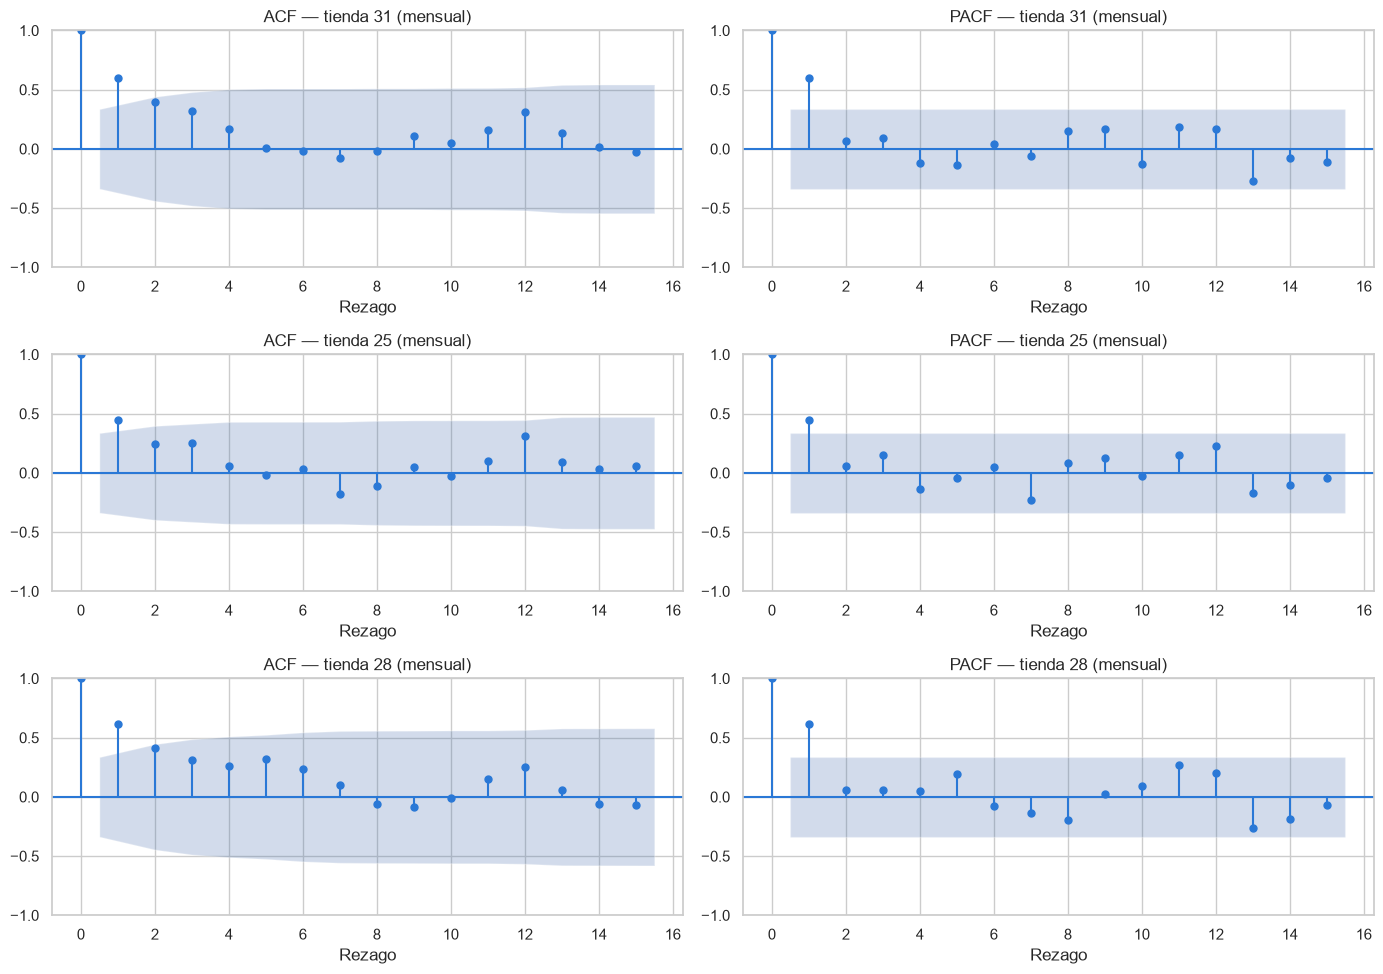

In [37]:
# 9.2 Ventas por sucursal: las 3 tiendas con más unidades entre las que venden los 34 meses
# (así la serie no mezcla meses cerrados con meses de baja venta).
tiendas_sel = comparacion_tiendas.query("meses_con_registros == 34").nlargest(3, "unidades_netas")
display(tiendas_sel[["shop_id", "shop_name", "unidades_netas"]])

fig, axes = plt.subplots(len(tiendas_sel), 2, figsize=(14, 3.3 * len(tiendas_sel)))
for fila, shop in zip(axes, tiendas_sel.shop_id):
    serie = serie_mensual(ventas_eda, shop_id=shop).set_index("fecha_mes")["unidades_netas"]
    series_acf[f"Tienda {shop}"] = (serie, 15, 12)
    graficar_acf_pacf(serie, f"tienda {shop} (mensual)", 15, axes=fila)
plt.tight_layout()
guardar_figura(fig, "9_2_acf_pacf_tiendas")
plt.show()

**Interpretación:**
- **Selección:** las tiendas **31, 25 y 28** (Moscú), las de mayor volumen entre las que venden los 34 meses.
- **Las tres repiten el patrón del total:**
  - ACF significativa solo en el **rezago 1** (0.60, 0.44 y 0.61) y decaimiento gradual.
  - PACF con un único rezago significativo (1), lo que indica un **AR(1)**.
- **Rezago 12:** la ACF tiene un pico local en las tres (0.31, 0.31 y 0.25) que refleja diciembre, pero no es significativo con 34 meses.
- **Estacionariedad (ADF):** la 25 es estacionaria (p = 0.009). La 31 y la 28 no lo son, por la tendencia descendente.
- **Implicación:** a nivel tienda, el mes anterior es el mejor predictor individual, y diciembre aparece como un pico recurrente.

### 9.3 Ventas por producto (selección representativa)

,item_id,item_name,meses_con_registros,unidades_netas
20602,20949,Фирменный пакет майка 1С Интерес белый (34*42)...,31,187642
2749,2808,"Diablo III [PC, Jewel, русская версия]",34,17245
17418,17717,Прием денежных средств для 1С-Онлайн,34,15830


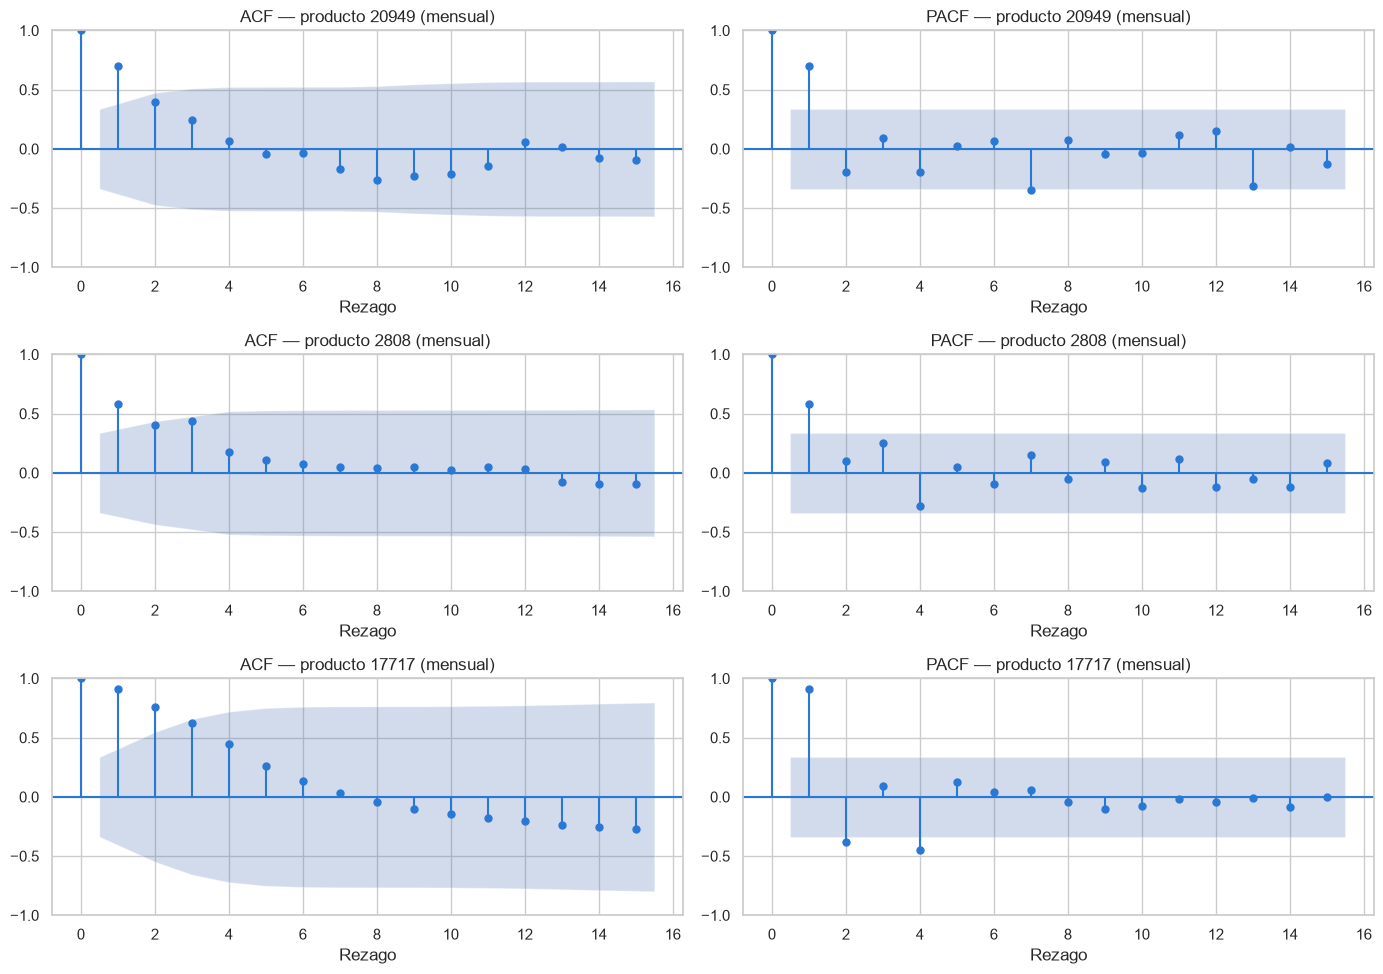

In [38]:
# 9.3 Ventas por producto: los 3 productos con más unidades entre los que tienen ventas en >= 30 de 34 meses.
# Los productos más vendidos suelen ser lanzamientos con vida corta; una serie casi toda en ceros no
# permite leer la ACF/PACF.
meses_producto = ventas_mensuales_por(ventas_eda, "item_id").groupby("item_id").date_block_num.nunique()
productos_sel = (
    resumen_productos.assign(meses_con_registros=resumen_productos.item_id.map(meses_producto))
    .query("meses_con_registros >= 30").nlargest(3, "unidades_netas")
)
display(productos_sel[["item_id", "item_name", "meses_con_registros", "unidades_netas"]])

fig, axes = plt.subplots(len(productos_sel), 2, figsize=(14, 3.3 * len(productos_sel)))
for fila, item in zip(axes, productos_sel.item_id):
    serie = serie_mensual(ventas_eda, item_id=item).set_index("fecha_mes")["unidades_netas"]
    series_acf[f"Producto {item}"] = (serie, 15, 12)
    graficar_acf_pacf(serie, f"producto {item} (mensual)", 15, axes=fila)
plt.tight_layout()
guardar_figura(fig, "9_3_acf_pacf_productos")
plt.show()

**Interpretación:**
- **Criterio de selección:** se exigieron **≥ 30 meses con ventas**. Los productos más vendidos en total suelen ser lanzamientos con vida corta (ver 10.a), cuyas series de 34 meses son casi todo ceros.
- **Productos seleccionados:** la **bolsa 20949**, **Diablo III para PC (2808)** y el servicio de cobro **1C-Online (17717)**. Que dos de los tres no sean mercancía tradicional muestra lo **poco comunes que son los productos con demanda estable** durante casi 3 años.
- **Las tres series tienen ACF significativa en el rezago 1** (0.70, 0.58 y 0.91). La 17717 muestra persistencia muy alta (rezagos 1 y 2), propia de una serie con tendencia creciente.
- **PACF:** significativa en el rezago 1 (y en 7 o en 2 y 4 en casos puntuales), lo que apunta a AR de orden bajo.
- **Rezago 12 ≈ 0** (entre −0.21 y 0.06): a nivel producto **no aparece estacionalidad anual**. El ciclo de vida del producto domina sobre el calendario.

### 9.4 Ventas por sucursal-producto (selección representativa)

Pares tienda-producto con historial: 418,909
Pares con ventas en >= 30 meses: 745 (0.18%)
Mediana de meses con ventas por par: 2


,shop_id,item_id,meses_con_registros,unidades_netas,item_name
0,31,20949,30,19934,Фирменный пакет майка 1С Интерес белый (34*42)...
1,12,11373,34,6563,Доставка до пункта выдачи (Boxberry)
2,12,11370,34,6163,Доставка (по Москве)


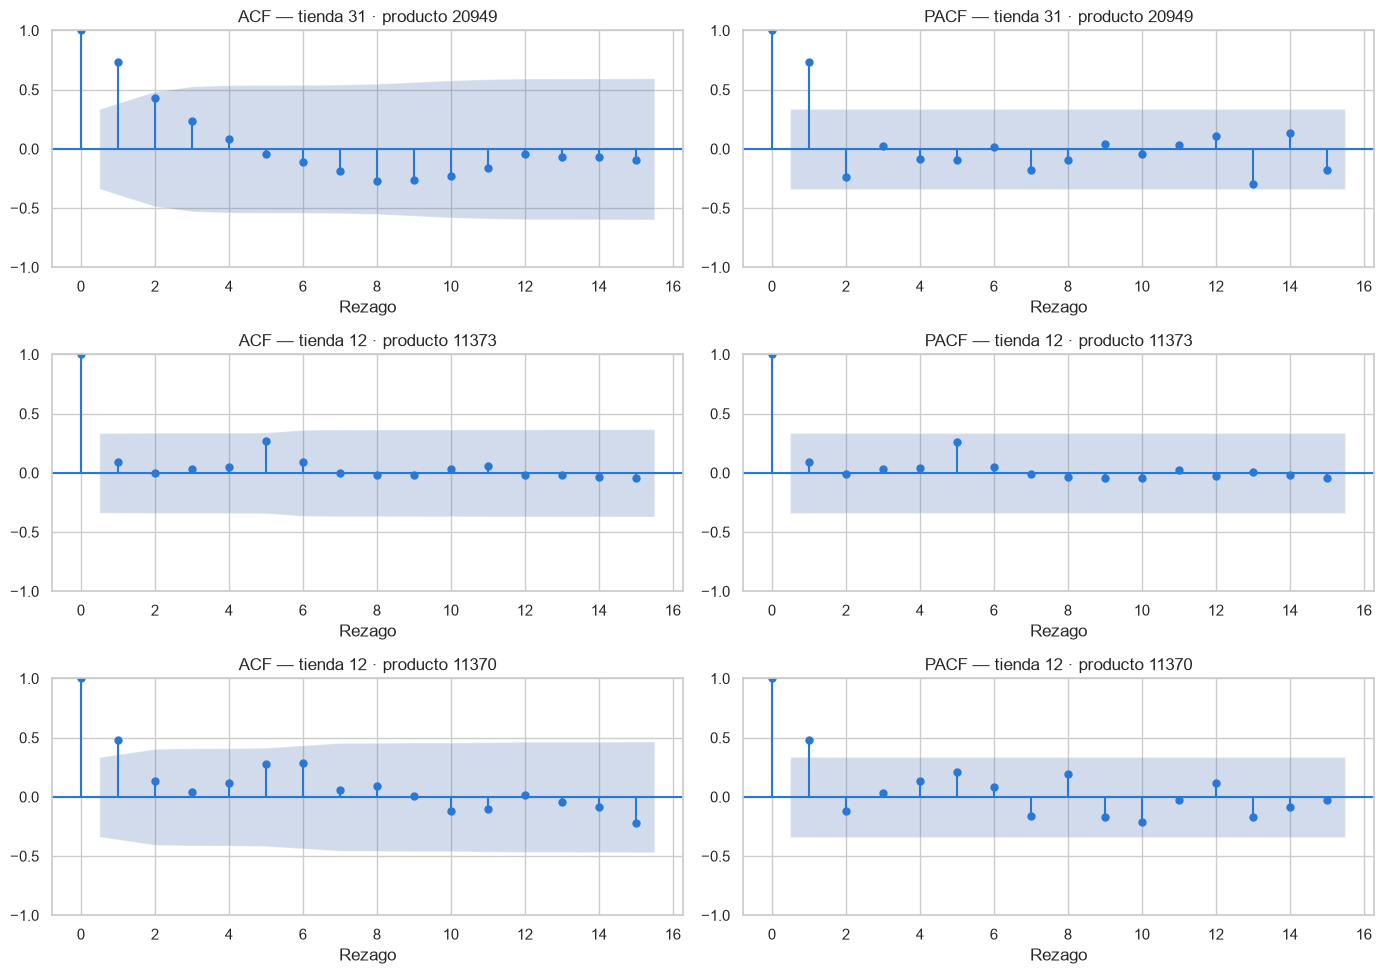

In [39]:
# 9.4 Ventas por sucursal-producto: los 3 pares con más unidades entre los que tienen ventas en >= 30 meses,
# tomando un solo par por producto (si no, los 3 serían de la bolsa 20949 en distintas tiendas).
pares_mes = ventas_mensuales_por(ventas_eda, ["shop_id", "item_id"])
pares = (
    pares_mes.groupby(["shop_id", "item_id"], as_index=False)
    .agg(meses_con_registros=("date_block_num", "nunique"), unidades_netas=("unidades_netas", "sum"))
)
print(f"Pares tienda-producto con historial: {len(pares):,}")
print(f"Pares con ventas en >= 30 meses: {(pares.meses_con_registros >= 30).sum():,} "
      f"({100 * (pares.meses_con_registros >= 30).mean():.2f}%)")
print(f"Mediana de meses con ventas por par: {pares.meses_con_registros.median():.0f}")
pares_sel = (
    pares.query("meses_con_registros >= 30").sort_values("unidades_netas", ascending=False)
    .drop_duplicates("item_id").head(3)
    .merge(items[["item_id", "item_name"]], on="item_id", how="left")
)
display(pares_sel)

fig, axes = plt.subplots(len(pares_sel), 2, figsize=(14, 3.3 * len(pares_sel)))
for fila, (shop, item) in zip(axes, pares_sel[["shop_id", "item_id"]].itertuples(index=False)):
    serie = serie_mensual(ventas_eda, shop_id=shop, item_id=item).set_index("fecha_mes")["unidades_netas"]
    series_acf[f"Tienda {shop} · producto {item}"] = (serie, 15, 12)
    graficar_acf_pacf(serie, f"tienda {shop} · producto {item}", 15, axes=fila)
plt.tight_layout()
guardar_figura(fig, "9_4_acf_pacf_tienda_producto")
plt.show()

**Interpretación:**
- **Pocos pares tienen historia larga:** de 418,909 pares tienda-producto con historial, **solo 745 (0.18 %)** venden en 30 meses o más, y la **mediana es de 2 meses con ventas**. La gran mayoría de las series tienda-producto son cortas e intermitentes.
- **Selección (un par por producto):**
  - **31 · 20949:** bolsa en la tienda principal; ACF(1) = 0.74 y AR(1) claro.
  - **12 · 11373:** entrega a punto de recogida Boxberry en la tienda en línea; **ningún rezago significativo**. La serie no se parece a sí misma mes a mes (ruido o cambios de nivel) y no es estacionaria (ADF p = 0.997).
  - **12 · 11370:** envío en Moscú; ACF(1) = 0.48 y PACF(1) significativa.
- **Rezago 12 ≈ 0 en los tres:** no hay estacionalidad anual.
- **Implicación:** las series largas a nivel tienda-producto son excepcionales (y en su mayoría servicios o la bolsa). Ajustar un ARIMA por par no es viable para los 214,200 pares de `test`. Conviene un **modelo global** (p. ej. de árboles) que use como variables los rezagos 1, 2, 3 y 12 de cada par, tienda y categoría.

### 9.5 Interpretación: rezagos significativos y estacionalidad

In [40]:
# 9.5 Resumen de todas las series: rezagos significativos (95 %), ACF en el rezago estacional
# (12 meses o 7 días) y prueba ADF (p < 0.05 -> la serie se puede considerar estacionaria).
resumen_acf = pd.DataFrame(
    {nombre: resumen_autocorrelacion(serie, lags, estacional) for nombre, (serie, lags, estacional) in series_acf.items()}
).T
display(resumen_acf)

# Misma lectura sobre la serie total mensual diferenciada (quita la tendencia descendente)
dif_total = serie_total_mes.diff().dropna()
print("Serie total mensual en primera diferencia:")
display(pd.Series(resumen_autocorrelacion(dif_total, 15, 12)).to_frame("Total mensual diferenciada").T)

,acf_rezago_1,rezagos_sig_acf,rezagos_sig_pacf,adf_p_valor,rezago_estacional,acf_estacional
Total (mensual),0.64,"1, 2",1,0.143,12,0.26
Total (diaria),0.68,"1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14,...","1, 2, 3, 5, 6, 7, 8, 9, 13, 14, 15, 16, 20, 21...",0.001,7,0.64
Tienda 31,0.6,1,1,0.101,12,0.31
Tienda 25,0.44,1,1,0.009,12,0.31
Tienda 28,0.61,1,1,0.16,12,0.25
Producto 20949,0.7,1,"1, 7",0.103,12,0.06
Producto 2808,0.58,1,1,0.058,12,0.03
Producto 17717,0.91,"1, 2","1, 2, 4",0.177,12,-0.21
Tienda 31 · producto 20949,0.74,1,1,0.144,12,-0.05
Tienda 12 · producto 11373,0.1,ninguno,ninguno,0.997,12,-0.02


Serie total mensual en primera diferencia:


,acf_rezago_1,rezagos_sig_acf,rezagos_sig_pacf,adf_p_valor,rezago_estacional,acf_estacional
Total mensual diferenciada,-0.29,12,"8, 11",0.0,12,0.45


**Interpretación — respuestas a 9.b:**

**i. ¿Existen correlaciones significativas a diferentes rezagos?**
- **Sí, en casi todas las series en el rezago 1** (ACF entre 0.44 y 0.91). En la PACF el rezago 1 es el único significativo en la mayoría, lo que apunta a un **AR(1)**: el mes anterior explica buena parte del mes actual.
- La serie total mensual añade el rezago 2 en la ACF.
- La serie diaria tiene **todos los rezagos hasta 49 significativos**, con máximos en los múltiplos de 7.
- La única serie sin rezagos significativos es 12 · 11373 (envío Boxberry).

**ii. ¿Se observa estacionalidad reflejada en patrones repetitivos?**
- **Semanal:** clara en la serie diaria (ACF de 0.64 en el rezago 7 y picos cada 7 días).
- **Anual (rezago 12):**
  - En niveles se ve solo como un pico local no significativo (0.25-0.31 en el total y las tiendas), porque la tendencia descendente y las 34 observaciones ensanchan la banda de confianza.
  - **Al diferenciar la serie total mensual** (quitar la tendencia), la ACF en el rezago 12 sube a **0.45 y es el único rezago significativo**, y la serie pasa a ser estacionaria (ADF p < 0.001). Hay estacionalidad anual (diciembre), aunque con solo dos ciclos completos.
  - **En productos y pares tienda-producto no hay estacionalidad anual** (ACF(12) ≈ 0). Ahí domina el ciclo de vida del producto.
- **Estacionariedad:** la mayoría de las series mensuales **no son estacionarias en nivel** (ADF p > 0.05), así que conviene diferenciar o modelar la tendencia.

**Para el forecasting:** usar como variables los **rezagos 1, 2, 3 y 12**, el **mes del año** (efecto diciembre) y la tendencia, construidos sobre la cuadrícula mensual tienda × producto con ceros.

## 10. Insights y conclusiones del EDA

### 10.a Variables que afectan directamente las ventas

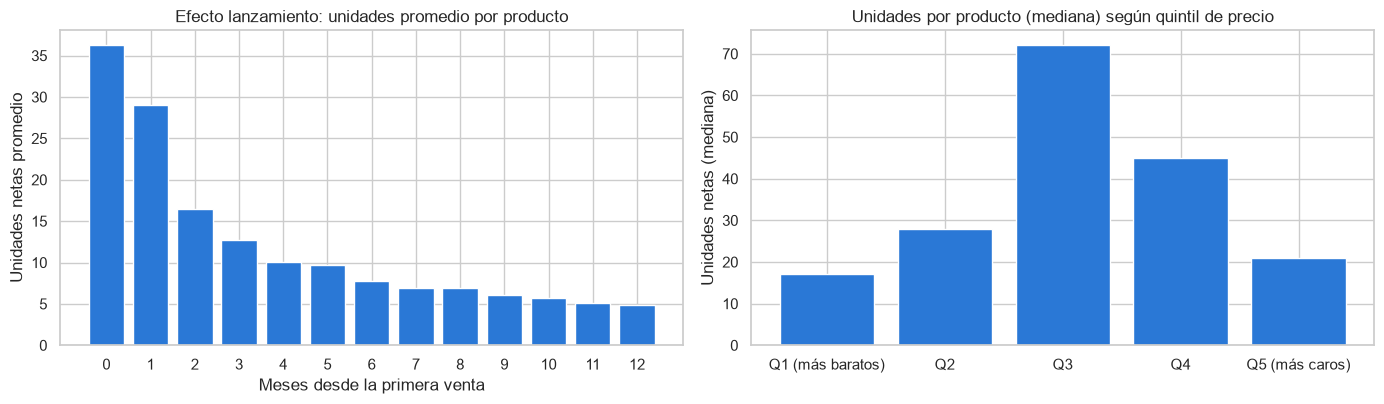

Productos con primera venta después de ene-2013: 13,692 de 21,807
Unidades del mes de lanzamiento vs. mes 1 vs. mes 6: 36.2 / 29.0 / 7.8


,quintil_precio,rango_precio,unidades_mediana_por_producto,pct_unidades,pct_ingresos
0,Q1 (más baratos),0 – 149,17.0,15.3,1.4
1,Q2,149 – 299,28.0,11.4,2.7
2,Q3,299 – 399,72.0,23.0,8.4
3,Q4,"399 – 1,049",45.0,27.0,20.8
4,Q5 (más caros),"1,049 – 307,980",21.0,23.4,66.6


Correlación de Spearman precio mediano vs. unidades por producto: 0.12


In [41]:
# 10.a Variables que afectan directamente las ventas: además de tienda, categoría y calendario
# (secciones 6-8), se miden el efecto lanzamiento (antigüedad del producto) y el precio.

# 1) Antigüedad: unidades promedio por producto según meses desde su primera venta.
#    Se excluyen productos con primera venta en ene-2013 (pudieron lanzarse antes: dato censurado).
item_mes = ventas_mensuales_por(ventas_eda, "item_id")
primer_mes = item_mes.groupby("item_id").date_block_num.min().rename("primer_mes")
item_mes = item_mes.join(primer_mes, on="item_id")
item_mes["antiguedad"] = item_mes.date_block_num - item_mes.primer_mes
lanzados = primer_mes[primer_mes > 0]
curva = []
for edad in range(13):
    elegibles = lanzados[lanzados <= 33 - edad].index  # productos que alcanzan esa antigüedad dentro del train
    unidades = item_mes.loc[item_mes.item_id.isin(elegibles) & (item_mes.antiguedad == edad), "unidades_netas"].sum()
    curva.append({"antiguedad_meses": edad, "unidades_promedio_por_producto": unidades / len(elegibles)})
curva = pd.DataFrame(curva)

# 2) Precio: unidades por producto según quintil de su precio mediano.
precio_producto = ventas_eda.groupby("item_id").item_price.median().rename("precio_mediano")
prod_precio = resumen_productos.join(precio_producto, on="item_id")
prod_precio["quintil_precio"] = pd.qcut(prod_precio.precio_mediano, 5, labels=["Q1 (más baratos)", "Q2", "Q3", "Q4", "Q5 (más caros)"])
por_quintil = prod_precio.groupby("quintil_precio", observed=True).agg(
    rango_precio=("precio_mediano", lambda s: f"{s.min():,.0f} – {s.max():,.0f}"),
    unidades_mediana_por_producto=("unidades_netas", "median"),
    pct_unidades=("unidades_netas", lambda s: 100 * s.sum() / prod_precio.unidades_netas.sum()),
    pct_ingresos=("ingresos_netos", lambda s: 100 * s.sum() / prod_precio.ingresos_netos.sum()),
).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
axes[0].bar(curva.antiguedad_meses, curva.unidades_promedio_por_producto, color=COLOR_PRINCIPAL)
axes[0].set(title="Efecto lanzamiento: unidades promedio por producto", xlabel="Meses desde la primera venta",
            ylabel="Unidades netas promedio", xticks=range(13))
axes[1].bar(por_quintil.quintil_precio.astype(str), por_quintil.unidades_mediana_por_producto, color=COLOR_PRINCIPAL)
axes[1].set(title="Unidades por producto (mediana) según quintil de precio", xlabel="", ylabel="Unidades netas (mediana)")
plt.tight_layout()
guardar_figura(fig, "10a_lanzamiento_y_precio")
plt.show()

print(f"Productos con primera venta después de ene-2013: {len(lanzados):,} de {len(primer_mes):,}")
print(f"Unidades del mes de lanzamiento vs. mes 1 vs. mes 6: "
      f"{curva.unidades_promedio_por_producto.iloc[0]:.1f} / {curva.unidades_promedio_por_producto.iloc[1]:.1f} / "
      f"{curva.unidades_promedio_por_producto.iloc[6]:.1f}")
display(por_quintil.round(1))
print(f"Correlación de Spearman precio mediano vs. unidades por producto: "
      f"{prod_precio.precio_mediano.corr(prod_precio.unidades_netas, method='spearman'):.2f}")

**Conclusiones — variables que afectan directamente las ventas:**
1. **Antigüedad del producto (efecto lanzamiento):** es el factor más fuerte a nivel producto. Un producto vende en promedio **36.2 unidades en su mes de lanzamiento**, **29.0** al mes siguiente y **7.8** a los seis meses: cae **~80 % en medio año**. Se excluyen del cálculo los productos que ya existían en ene-2013, porque no se conoce su lanzamiento real.
2. **Ventas recientes (rezagos):** la ACF y la PACF muestran que el mes anterior es el mejor predictor (AR(1), sección 9).
3. **Tienda:** las diferencias de nivel son muy grandes (la mayor vende 5.8 veces la mediana). También importan su ubicación (Moscú), su tipo (en línea, digital, de evento) y si está abierta o cerrada.
4. **Categoría o grupo:** define el volumen y el precio típico. Cine, Juegos PC, Juegos de consola, Regalos y Música concentran ~89 % de las unidades, y la mezcla cambia en el tiempo (8.d).
5. **Calendario:** **diciembre** (+41 % en 2013 y +43 % en 2014 frente a noviembre) y tendencia descendente general. A nivel diario, los fines de semana.
6. **Precio:** su relación con las unidades es **débil y no lineal** (Spearman 0.12). Los productos de precio medio (Q3: 299-399) tienen la mediana más alta de unidades. Los más caros (Q5) son el 23.4 % de las unidades pero el **66.6 % de los ingresos**: el precio explica más los ingresos que las unidades.

Variables como promociones, inventario o lanzamientos anunciados no están en el dataset.

### 10.b Patrones útiles para el forecasting (% de pares de `test.csv` con historial en train)

In [42]:
# 10.b Cobertura de test.csv: ¿cuántos pares tienda-producto tienen historial en el train?
test_cov = cobertura_test(test, ventas_eda)
cobertura = test_cov.historial.value_counts().rename("pares").to_frame()
cobertura["pct"] = (100 * cobertura.pares / len(test_cov)).round(2)
display(cobertura)

print(f"Tiendas en test: {test.shop_id.nunique()} (todas con historial en train: {test.shop_id.isin(ventas_eda.shop_id).all()})")
print(f"Productos en test: {test.item_id.nunique():,}; nuevos (sin ninguna venta en train): "
      f"{test_cov.loc[test_cov.historial == 'producto nuevo', 'item_id'].nunique():,}")
print(f"Tiendas del train que no están en test: {sorted(set(ventas_eda.shop_id) - set(test.shop_id))}")

# Actividad reciente de los pares con historial (el último mes es el mejor predictor ingenuo)
ultimo_par = pares_mes.groupby(["shop_id", "item_id"]).date_block_num.max().rename("ultimo_mes")
con_hist = test_cov.query("historial == 'par con historial'").join(ultimo_par, on=["shop_id", "item_id"])
print(f"De los pares con historial: {100 * (con_hist.ultimo_mes == 33).mean():.1f}% vendió en oct-2015 y "
      f"{100 * (con_hist.ultimo_mes >= 31).mean():.1f}% en los últimos 3 meses")

# Productos nuevos: ¿de qué grupos de categoría son?
nuevos = (test_cov.query("historial == 'producto nuevo'")[["item_id"]].drop_duplicates()
          .merge(items[["item_id", "item_category_id"]], on="item_id")
          .merge(categorias_grupo[["item_category_id", "grupo_categoria"]], on="item_category_id"))
print("Productos nuevos de test por grupo de categoría:")
display(nuevos.grupo_categoria.value_counts().head(8).rename("productos_nuevos").to_frame())

,pares,pct
historial,,
par con historial,111471,52.04
"producto conocido, par nuevo",87483,40.84
producto nuevo,15246,7.12


Tiendas en test: 42 (todas con historial en train: True)
Productos en test: 5,100; nuevos (sin ninguna venta en train): 363


Tiendas del train que no están en test: [8, 9, 13, 17, 20, 23, 27, 29, 30, 32, 33, 40, 43, 51, 54]


De los pares con historial: 25.7% vendió en oct-2015 y 50.2% en los últimos 3 meses
Productos nuevos de test por grupo de categoría:


,productos_nuevos
grupo_categoria,
Cine,74
Regalos,67
Música,66
Juegos de consola,45
Libros,44
Juegos PC,38
Programas,18
Consolas,6


**Conclusiones — patrones útiles para el forecasting:**
- **Cobertura de `test.csv`:**
  - Solo el **52.04 % de los pares tienda-producto (111,471) tiene historial** en el train.
  - El **40.84 % (87,483)** es de productos que sí se vendieron, pero nunca en esa tienda.
  - El **7.12 % (15,246 pares, 363 productos)** son **productos nuevos** sin ninguna venta en train, sobre todo de Cine, Regalos y Música.
- **Tiendas:** las 42 tiendas de `test` tienen historial. Las 15 tiendas del train que no están en `test` incluyen las cerradas y las de evento (9 y 20).
- **Aun con historial, la mayoría de los pares no vendió recientemente:** solo el **25.7 %** vendió en oct-2015 y el **50.2 %** en los últimos 3 meses. Como `test` es una cuadrícula completa (42 tiendas × 5,100 productos), **la mayoría de los valores a predecir serán 0**.
- **Patrones a aprovechar:**
  - Construir el train en el **mismo formato de cuadrícula mensual** (tienda × producto con ceros, DEC-008) para que el modelo aprenda a predecir ceros.
  - Usar **rezagos 1, 2, 3 y 12** de par, producto, tienda y categoría.
  - Agregar **mes del año**: noviembre fue +1.9 % (2013) y +9.7 % (2014) sobre octubre, antes del pico de diciembre.
  - Agregar **meses desde el lanzamiento** del producto y **meses desde la primera venta en la tienda**.
  - Para pares y productos sin historial, usar promedios de categoría o tienda y la curva de lanzamiento (10.a).
  - Los extremos (p. ej. 2,169 unidades en un día) pesan mucho. Kaggle evalúa con el objetivo recortado a [0, 20], así que se recomienda decidir el recorte en modelado.

### 10.c Calidad y preparación del dataset para las siguientes etapas

In [43]:
# 10.c Resumen de calidad y preparación (valores calculados en este notebook).
nulos_totales = sum(int(df.isna().sum().sum()) for df in datos.values())
pares_mes_negativos = int((pares_mes.unidades_netas < 0).sum())
calidad = pd.DataFrame([
    ("Valores nulos (5 tablas crudas)", f"{nulos_totales}", "Sin tratamiento (DEC-008)"),
    ("Duplicados exactos en sales_train", f"6 eliminados; {ventas_eda.drop(columns='ingresos').duplicated().sum()} restantes", "DEC-010"),
    ("Precios <= 0", f"1 corregido; {(ventas_eda.item_price <= 0).sum()} restantes", "DEC-009"),
    ("Devoluciones (cantidades < 0)", f"{(ventas_eda.item_cnt_day < 0).sum():,} ({100 * (ventas_eda.item_cnt_day < 0).mean():.2f}%)", "Se conservan (DEC-009)"),
    ("Meses tienda-producto con neto < 0", f"{pares_mes_negativos:,}", "Se decide en modelado (DEC-009)"),
    ("Tiendas duplicadas", "60 -> 57 tiendas", "DEC-011"),
    ("Consistencia date_block_num vs. fecha", "100 %", "DEC-007"),
    ("Registros > p99.9 en precio o cantidad", f"{len(alertas):,}", "Se conservan; revisar en modelado (DEC-013)"),
    ("Pares de test con historial", f"{cobertura.loc['par con historial', 'pct']:.1f}%", "El resto requiere estrategia de arranque en frío"),
], columns=["Aspecto", "Resultado", "Tratamiento / decisión"])
display(calidad)

,Aspecto,Resultado,Tratamiento / decisión
0,Valores nulos (5 tablas crudas),0,Sin tratamiento (DEC-008)
1,Duplicados exactos en sales_train,6 eliminados; 0 restantes,DEC-010
2,Precios <= 0,1 corregido; 0 restantes,DEC-009
3,Devoluciones (cantidades < 0),"7,356 (0.25%)",Se conservan (DEC-009)
4,Meses tienda-producto con neto < 0,915,Se decide en modelado (DEC-009)
5,Tiendas duplicadas,60 -> 57 tiendas,DEC-011
6,Consistencia date_block_num vs. fecha,100 %,DEC-007
7,Registros > p99.9 en precio o cantidad,"5,811",Se conservan; revisar en modelado (DEC-013)
8,Pares de test con historial,52.0%,El resto requiere estrategia de arranque en frío


**Conclusiones — calidad y preparación del dataset:**

**Calidad:** el dataset tiene **buena calidad estructural**.
- No hay nulos.
- Se encontraron solo **6 duplicados exactos** y **1 precio inválido**, ambos corregidos.
- `date_block_num` coincide con la fecha en el 100 % de las filas.
- Las 3 tiendas duplicadas quedaron unificadas (60 → 57).
- Las devoluciones (0.25 %) son transacciones reales y se conservan.

**Pendiente para modelado (no son errores, son decisiones):**
1. **Cuadrícula mensual tienda × producto con ceros:** `sales_train` solo registra lo vendido y `test` es una cuadrícula completa.
2. **Meses con neto negativo (915) y valores extremos (5,811 registros sobre el p99.9):** decidir si se recortan, por ejemplo a [0, 20] como en la evaluación de Kaggle.
3. **Tiendas cerradas o de evento** (54, 9, 20, etc.): decidir si se excluyen del entrenamiento, porque no están en `test`.
4. **Arranque en frío** para el 48 % de los pares de `test` sin historial, incluido el 7 % de productos nuevos.
5. **Validación temporal:** usar oct-2015 (mes 33) como validación, imitando la predicción de nov-2015, sin mezclar meses futuros en el entrenamiento.
6. **Memoria:** la cuadrícula mensual completa tendrá millones de filas, así que conviene usar tipos más livianos (`int16`/`float32`).

**Conclusión general:** las ventas tienen **tendencia descendente, estacionalidad de fin de año, fuerte dependencia del mes anterior** y una **alta concentración** en pocas tiendas y categorías. A nivel tienda-producto, las series son cortas, intermitentes y dominadas por el ciclo de vida del producto. Por eso se recomienda un modelo global con variables de rezagos, calendario, tienda, categoría y antigüedad, en lugar de modelos individuales por serie.